# CICEVSE2024 - Preliminary Results for the AI-SOC Capstone
**What this notebook does** (run top to bottom; every cell prints what it found):
1. Cleans each source (incl. the host-file label repair found in the audit)
2. Plots class distributions (dataset justification evidence)
3. Checks whether the three sources can be aligned in time
4. Trains baselines (Dummy -> Logistic Regression -> Random Forest) with a **blocked, leakage-aware split**
5. Runs a separate Isolation Forest anomaly experiment on Power
6. Writes a sample structured alert (the interface to your agentic layer)

All outputs go to the `preliminary_results/` folder next to this notebook.
Nothing here is a final result: it is a first, honest baseline.

## 0. Configuration

In [24]:

import os
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 40)

# ============================================================
# CONFIGURATION
# ============================================================

SEED = 42

# Project directory
DATA_DIR = Path(
    os.environ.get("EV_DATA_DIR", r"D:\Dharini\Capstone")
)
BASE = DATA_DIR

# Output directory
RESULTS = Path("preliminary_results")
RESULTS.mkdir(exist_ok=True)

# Dataset paths
FILES = {
    "power": DATA_DIR / "Power Consumption" / "EVSE-B-PowerCombined.csv",
    "host": DATA_DIR / "Host Events" / "EVSE-B-HPC-Kernel-Events-Combined.csv",
    "netA": DATA_DIR / "Network Traffic" / "EVSE-A-Network-Combined.csv",
    "netB": DATA_DIR / "Network Traffic" / "EVSE-B-Network-Combined.csv",
}
# Network Combined files are not in the D: folder; point them to where v1 found them
FILES["netA"] = Path(r"E:\Dataset\extracted\Network Traffic\EVSE-A-Network-Combined.csv")
FILES["netB"] = Path(r"E:\Dataset\extracted\Network Traffic\EVSE-B-Network-Combined.csv")
# Network sampling
# EVSE-B is approximately 2.2 million rows.
NET_CHUNK = int(os.environ.get("EV_NET_CHUNK", 250_000))
NET_CAP_PER_CLASS_PER_CHUNK = 4_000
MIN_CLASS_SAMPLES = 200

# Rows per contiguous block for train/test splitting
BLOCK_ROWS = {
    "power": 500,
    "host": 50,
    "net": 2000,
}

USE_DST_PORT = True

# Logging and experiment summaries
CLEANING_LOG = []
SUMMARY = []


def log(msg):
    print("•", msg)
    CLEANING_LOG.append(msg)


# Host dataset cleaning option
DROP_OLD_ICMP_FRAG = False

# Per-scenario folders
DIRS = {
    "host_individual": DATA_DIR / "Host Events" / "Individual Files",
    "netA_csv": DATA_DIR / "Network Traffic" / "EVSE-A" / "csv",
    "netB_csv": DATA_DIR / "Network Traffic" / "EVSE-B" / "csv",
}

# ============================================================
# VERIFY DATASET PATHS
# ============================================================

print("=" * 70)
print("PROJECT DIRECTORY")
print("=" * 70)
print(f"Project directory: {DATA_DIR.resolve()}")
print(f"Project directory exists: {DATA_DIR.exists()}")

print("\n" + "=" * 70)
print("COMBINED DATASET FILES")
print("=" * 70)

missing_files = []

for name, path in FILES.items():
    exists = path.is_file()
    status = "FOUND" if exists else "MISSING"
    print(f"{name:6s} {status:8s} {path}")

    if not exists:
        missing_files.append((name, path))

print("\n" + "=" * 70)
print("SCENARIO FOLDERS")
print("=" * 70)

for name, path in DIRS.items():
    status = "FOUND" if path.is_dir() else "MISSING"
    print(f"{name:16s} {status:8s} {path}")

# ============================================================
# REPORT MISSING FILES
# ============================================================

if missing_files:
    print("\nWARNING: The following dataset files could not be found:")

    for name, path in missing_files:
        print(f"  - {name}: {path}")

    print(
        "\nCheck the filenames and folder locations in VS Code. "
        "Do not proceed with cells that load missing files."
    )
else:
    print("\nAll four combined dataset files were found.")
    print("You can proceed to the dataset-loading cells.")


PROJECT DIRECTORY
Project directory: D:\Dharini\Capstone
Project directory exists: True

COMBINED DATASET FILES
power  FOUND    D:\Dharini\Capstone\Power Consumption\EVSE-B-PowerCombined.csv
host   FOUND    D:\Dharini\Capstone\Host Events\EVSE-B-HPC-Kernel-Events-Combined.csv
netA   MISSING  E:\Dataset\extracted\Network Traffic\EVSE-A-Network-Combined.csv
netB   MISSING  E:\Dataset\extracted\Network Traffic\EVSE-B-Network-Combined.csv

SCENARIO FOLDERS
host_individual  FOUND    D:\Dharini\Capstone\Host Events\Individual Files
netA_csv         FOUND    D:\Dharini\Capstone\Network Traffic\EVSE-A\csv
netB_csv         FOUND    D:\Dharini\Capstone\Network Traffic\EVSE-B\csv

  - netA: E:\Dataset\extracted\Network Traffic\EVSE-A-Network-Combined.csv
  - netB: E:\Dataset\extracted\Network Traffic\EVSE-B-Network-Combined.csv

Check the filenames and folder locations in VS Code. Do not proceed with cells that load missing files.


In [25]:
def segment_ids(attack, state):
    """Recover recordings in the Combined files: a new id starts whenever attack or state changes."""
    key = pd.Series(np.asarray(attack)).astype(str) + "|" + pd.Series(np.asarray(state)).astype(str)
    return (key != key.shift()).cumsum().values

def recording_split(y, groups, test_frac=0.33, seed=SEED):
    """Hold out whole recordings. Classes with a single recording stay in train only."""
    rng = np.random.default_rng(seed)
    d = pd.DataFrame({"y": np.asarray(y), "g": np.asarray(groups)})
    test_groups, single = set(), []
    for cls, sub in d.groupby("y"):
        recs = sub["g"].unique()
        if len(recs) < 2:
            single.append(cls); continue
        k = max(1, int(round(len(recs) * test_frac)))
        test_groups.update(rng.choice(recs, size=k, replace=False))
    te = d["g"].isin(test_groups).values
    if single:
        print("   single-recording classes (train only, not evaluated):", single)
    return np.where(~te)[0], np.where(te)[0]

## 0b. File inventory of the per-scenario files (provenance + integrity check)
Question answered: *do the "Combined" files equal the sum of the individual scenario files, and where is the benign data?*
File names carry the experiment design: **state** (charging / idle), **attacker** (normal vs `MaliciousEV`), **attack type**.

In [26]:
def count_data_rows(path: Path) -> int:
    """Fast row count (newlines minus header). Assumes no embedded newlines in fields (true for these CSVs)."""
    n = 0
    with open(path, "rb") as f:
        while chunk := f.read(1 << 24):
            n += chunk.count(b"\n")
    return max(n - 1, 0)

def describe_file(path: Path, device: str) -> dict:
    low = path.stem.lower()
    return {"device": device, "file": path.name,
            "state": "charging" if "charging" in low else ("idle" if "idle" in low else "unknown"),
            "attacker": "MaliciousEV" if "maliciousev" in low else "standard",
            "is_benign": "benign" in low,
            "size_MB": round(path.stat().st_size / 2**20, 1),
            "rows": count_data_rows(path)}

inv_rows = []
for key, dev in [("netA_csv", "EVSE-A network"), ("netB_csv", "EVSE-B network"), ("host_individual", "EVSE-B host")]:
    if DIRS[key].exists():
        inv_rows += [describe_file(p, dev) for p in sorted(DIRS[key].glob("*.csv"))]
file_inv = pd.DataFrame(inv_rows)
if len(file_inv):
    file_inv.to_csv(RESULTS / "file_inventory.csv", index=False)
    display(file_inv.groupby(["device", "state", "attacker", "is_benign"]).agg(files=("file", "count"), rows=("rows", "sum")))
    print("\nBenign scenario files and their row counts:")
    display(file_inv[file_inv.is_benign][["device", "file", "state", "rows"]])
    combined_rows = {"EVSE-A network": 547_854, "EVSE-B network": 2_196_846, "EVSE-B host": 8_474}   # from your audit
    chk = file_inv.groupby("device")["rows"].sum().to_frame("sum of individual files")
    chk["rows in Combined file (audit)"] = pd.Series(combined_rows)
    display(chk)
    print("If these differ, the Combined file is NOT simply all individual files -> note it in the report.")
else:
    print("No per-scenario folders found - check DIRS paths.")

files     rows
device         state    attacker    is_benign                
EVSE-A network charging standard    False         14   315709
                                    True           1       14
               idle     standard    False         12   232063
                                    True           1       68
EVSE-B host    charging standard    False         15  4945882
                                    True           1  1296411
               idle     standard    False         17  3387154
                                    True           1  1371117
               unknown  MaliciousEV False          6   388348
                        standard    False          1    59460
EVSE-B network charging standard    False         12  1043325
               idle     standard    False         13   588740
               unknown  MaliciousEV False          6   564781


Benign scenario files and their row counts:


,device,file,state,rows
1,EVSE-A network,EVSE-A-Charging-Benign.csv,charging,14
16,EVSE-A network,EVSE-A-idle-benign.csv,idle,68
61,EVSE-B host,EVSE-B-charging-benign.csv,charging,1296411
78,EVSE-B host,EVSE-B-idle-benign_updated.csv,idle,1371117


,sum of individual files,rows in Combined file (audit)
device,,
EVSE-A network,547854,547854
EVSE-B host,11448372,8474
EVSE-B network,2196846,2196846


If these differ, the Combined file is NOT simply all individual files -> note it in the report.


## 1. Label harmonisation (one mapping, raw labels always kept)
The audit showed typos / variants (`serice-detection`, `icmp-fragmentation_old`, `Backdoor` vs `backdoor`).
**Assumption to confirm with the dataset paper:** `os-scan` == `os-fingerprinting`.
`slowloris` is DoS in your EVSE-A files (the website lists it under recon) - we follow the file's `Attack-Group`.

In [27]:
NAME_FIX = {
    "serice-detection": "service-detection",
    "icmp-fragmentation_old": "icmp-fragmentation",
    "os-scan": "os-fingerprinting",
    "none": "benign", "0": "benign",
}
ATTACK_TO_GROUP = {
    "benign": "none",
    "port-scan": "recon", "vuln-scan": "recon", "syn-stealth": "recon",
    "aggressive-scan": "recon", "service-detection": "recon", "os-fingerprinting": "recon",
    "slowloris": "DoS", "icmp-flood": "DoS", "push-ack-flood": "DoS", "syn-flood": "DoS",
    "tcp-flood": "DoS", "synonymous-ip-flood": "DoS", "udp-flood": "DoS", "icmp-fragmentation": "DoS",
    "cryptojacking": "host-attack", "backdoor": "host-attack",
}
def norm_attack(s: pd.Series) -> pd.Series:
    s = s.astype("string").str.strip().str.lower()
    return s.replace(NAME_FIX)
def norm_group(s: pd.Series) -> pd.Series:
    s = s.astype("string").str.strip()
    return s.replace({"dos": "DoS", "Dos": "DoS", "None": "none", "NONE": "none"})

## 2. Power (EVSE-B) - the cleanest source and the one with a real benign share

In [28]:
power = pd.read_csv(FILES["power"], low_memory=False)
n0 = len(power)
power["attack_norm"] = norm_attack(power["Attack"])
power["group_norm"] = norm_group(power["Attack-Group"])
power["is_attack"] = (power["Label"].astype("string").str.lower() == "attack").astype(int)
power["state_charging"] = (power["State"].astype("string").str.lower() == "charging").astype(int)
power["row_no"] = np.arange(len(power))
print("State values:", power["State"].value_counts().to_dict())
log(f"Power: {n0:,} rows kept. 1,100 exact duplicates NOT dropped: timestamps are minute-level with up to 59 readings/minute, "
    "so repeats are plausible repeated sensor readings; blocked split prevents them leaking across train/test.")
POWER_FEATS = ["shunt_voltage", "bus_voltage_V", "current_mA", "power_mW", "state_charging"]
display(power[["attack_norm", "group_norm", "is_attack"]].value_counts().rename("rows").to_frame())

State values: {'idle': 85705, 'charging': 29593}
• Power: 115,298 rows kept. 1,100 exact duplicates NOT dropped: timestamps are minute-level with up to 59 readings/minute, so repeats are plausible repeated sensor readings; blocked split prevents them leaking across train/test.


,,,rows
attack_norm,group_norm,is_attack,
vuln-scan,recon,1,26246
tcp-flood,DoS,1,21367
backdoor,host-attack,1,21137
benign,none,0,14363
syn-flood,DoS,1,13517
cryptojacking,host-attack,1,11596
syn-stealth,recon,1,7072


## 3. Host (EVSE-B) - repair the stacked file
The audit found two files stacked (an embedded header around row 6169). In the 2nd block the real labels sit in
`Unnamed: 911-914`, while `State/Attack/Scenario/Label` hold `0`. We rebuild the labels and drop unusable rows.

In [29]:
host_raw = pd.read_csv(FILES["host"], low_memory=False)
unn = [c for c in host_raw.columns if str(c).startswith("Unnamed:")]
meta = ["State", "Attack", "Scenario", "Label", "interface"] + unn
counter_cols = [c for c in host_raw.columns if c not in meta and c != "time"]

# block-2 rows: label text lives in the first "Unnamed" column (and is not the embedded header word "Attack")
b2 = host_raw[unn[0]].notna() & (host_raw[unn[0]].astype("string") != "Attack")
attack_raw = host_raw["Attack"].where(~b2, host_raw[unn[0]])
label_raw  = host_raw["Label"].where(~b2, host_raw[unn[2]])
state_raw  = host_raw["State"].where(~b2, host_raw["interface"])   # block 2 keeps State text in the old 'interface' column

X_host_all = host_raw[counter_cols].apply(pd.to_numeric, errors="coerce")
valid = X_host_all.notna().mean(axis=1) > 0.5          # drops blank rows + the embedded header row
if DROP_OLD_ICMP_FRAG:
    old = attack_raw.astype("string").str.strip().str.lower().eq("icmp-fragmentation_old")
    log(f"Host: dropped {int((old & valid).sum())} rows from the superseded icmp-fragmentation_old scenario.")
    valid &= ~old
log(f"Host: {len(host_raw):,} raw rows -> {int(valid.sum()):,} usable; dropped {int((~valid).sum())} blank/header/stray rows.")

host = pd.DataFrame({
    "attack_norm": norm_attack(attack_raw)[valid].values,
    "label_raw": label_raw.astype("string")[valid].values,
    "state": state_raw.astype("string")[valid].values,
    "block2": b2[valid].values,
})
host["is_attack"] = (host["attack_norm"] != "benign").astype(int)
host["group_norm"] = host["attack_norm"].map(ATTACK_TO_GROUP)
unmapped = host.loc[host["group_norm"].isna(), "attack_norm"].value_counts()
if len(unmapped):
    print("!! Attack names not in ATTACK_TO_GROUP (add them):", unmapped.to_dict())
    host["group_norm"] = host["group_norm"].fillna("unmapped")
X_host = X_host_all[valid].reset_index(drop=True)
const = [c for c in X_host.columns if X_host[c].nunique(dropna=True) <= 1]
X_host = X_host.drop(columns=const)
log(f"Host: dropped {len(const)} constant/empty counter columns; {X_host.shape[1]} usable features remain "
    f"for {len(X_host):,} rows (high feature:row ratio -> overfitting risk).")
host["row_no"] = np.arange(len(host))
print("Cross-check - label_raw vs repaired attack flag:")
display(pd.crosstab(host["label_raw"], host["is_attack"]))
display(host["attack_norm"].value_counts().to_frame("rows"))

• Host: 8,474 raw rows -> 8,468 usable; dropped 6 blank/header/stray rows.
• Host: dropped 622 constant/empty counter columns; 283 usable features remain for 8,468 rows (high feature:row ratio -> overfitting risk).
Cross-check - label_raw vs repaired attack flag:


is_attack,0,1
label_raw,,
attack,0,6166
benign,2302,0


,rows
attack_norm,
benign,2302
backdoor,2302
cryptojacking,1793
port-scan,201
service-detection,199
vuln-scan,192
syn-stealth,189
aggressive-scan,182
os-fingerprinting,182


## 4. Network (EVSE-A and EVSE-B) - sampled, leakage columns removed
Removed on purpose: ids, IPs, MACs, OUIs, `src_port`, all absolute timestamps, `source_file`, `device`,
string/application columns, and the 5 columns that are >99.9% empty.

In [30]:
NET_EXCLUDE = {
    "id", "expiration_id", "src_ip", "src_mac", "src_oui", "src_port", "dst_ip", "dst_mac", "dst_oui",
    "vlan_id", "tunnel_id", "bidirectional_first_seen_ms", "bidirectional_last_seen_ms",
    "src2dst_first_seen_ms", "src2dst_last_seen_ms", "dst2src_first_seen_ms", "dst2src_last_seen_ms",
    "application_name", "application_category_name", "requested_server_name", "client_fingerprint",
    "server_fingerprint", "user_agent", "content_type", "device", "State", "Attack", "Attack-Group",
    "Label", "source_file",
}
if not USE_DST_PORT:
    NET_EXCLUDE.add("dst_port")

def load_network(path: Path, name: str):
    rng = np.random.default_rng(SEED)
    header = pd.read_csv(path, nrows=0).columns
    feats = [c for c in header if c not in NET_EXCLUDE]
    use = feats + ["Attack", "Attack-Group", "Label", "source_file"]
    parts, offset, counts = [], 0, pd.Series(dtype="int64")
    for chunk in pd.read_csv(path, usecols=use, chunksize=NET_CHUNK, low_memory=False):
        chunk["row_no"] = np.arange(offset, offset + len(chunk)); offset += len(chunk)
        counts = counts.add(chunk["Attack"].astype("string").value_counts(), fill_value=0)   # exact totals
        r = pd.Series(rng.random(len(chunk)), index=chunk.index)
        rank = r.groupby(chunk["Attack"].astype("string")).rank(method="first")
        parts.append(chunk[rank <= NET_CAP_PER_CLASS_PER_CHUNK])
    df = pd.concat(parts, ignore_index=True)
    df["attack_norm"] = norm_attack(df["Attack"])
    df["group_norm"] = norm_group(df["Attack-Group"])
    df["block"] = df["source_file"].astype("string") + "_" + (df["row_no"] // BLOCK_ROWS["net"]).astype(str)
    totals = norm_attack(pd.Series(counts.index, index=counts.index)).to_frame("a").assign(n=counts.values).groupby("a")["n"].sum().astype(int)
    log(f"{name}: read {offset:,} rows, sampled {len(df):,} ({len(feats)} candidate features).")
    return {"df": df, "feats": feats, "total": offset, "totals": totals}

net = {}
for key, nm in [("netA", "Network EVSE-A"), ("netB", "Network EVSE-B")]:
    if FILES[key].exists():
        net[key] = load_network(FILES[key], nm)
        display(net[key]["totals"].to_frame("exact rows in file").T)

# Extra benign flows for EVSE-A: the Combined file has very few, but the tree shows dedicated benign CSVs.
benign_A = None
if "netA" in net and DIRS["netA_csv"].exists():
    frames = []
    for p in sorted(DIRS["netA_csv"].glob("*.csv")):
        if "benign" in p.stem.lower():
            hdr = pd.read_csv(p, nrows=0).columns
            cols = [c for c in net["netA"]["feats"] if c in hdr]
            d = pd.read_csv(p, usecols=cols, low_memory=False)
            d["row_no"] = np.arange(len(d)); d["source_file"] = p.name
            d["attack_norm"] = "benign"; d["group_norm"] = "none"
            d["block"] = d["source_file"] + "_" + (d["row_no"] // BLOCK_ROWS["net"]).astype(str)
            frames.append(d)
            print(f"  benign file {p.name}: {len(d):,} flows, {len(cols)}/{len(net['netA']['feats'])} feature columns present")
    if frames:
        benign_A = pd.concat(frames, ignore_index=True)
        log(f"EVSE-A: {len(benign_A):,} benign flows loaded from dedicated benign CSVs (Combined file only had "
            f"{int(net['netA']['totals'].get('benign', 0)):,}). Compare these with the Combined file before merging them.")

## 5. Class-distribution plots (use these in the Dataset Justification slide)

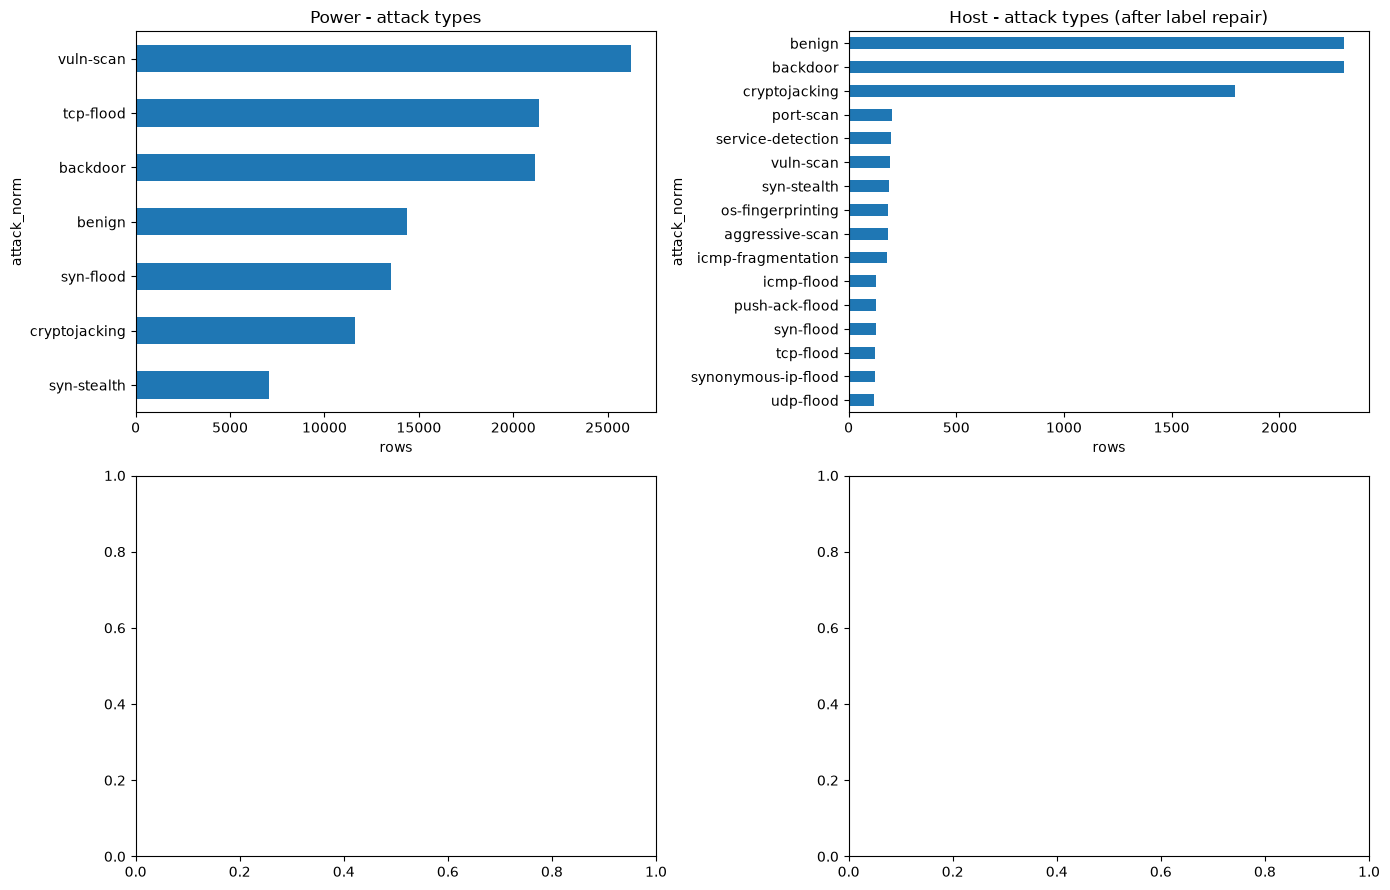

,source,rows,benign,attack
0,Power (EVSE-B),115298,14363,100935
1,Host (EVSE-B),8468,2302,6166


In [31]:
def bar(ax, s, title):
    s.value_counts().sort_values().plot.barh(ax=ax)
    ax.set_title(title); ax.set_xlabel("rows")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
bar(axes[0, 0], power["attack_norm"], "Power - attack types")
bar(axes[0, 1], host["attack_norm"], "Host - attack types (after label repair)")
for ax, key, t in [(axes[1, 0], "netA", "Network EVSE-A (sampled)"), (axes[1, 1], "netB", "Network EVSE-B (sampled)")]:
    if key in net:
        bar(ax, net[key]["df"]["attack_norm"], t + " - attack types")
plt.tight_layout(); plt.savefig(RESULTS / "class_distribution.png", dpi=150); plt.show()

inv = pd.DataFrame([
    {"source": "Power (EVSE-B)", "rows": len(power), "benign": int((power.is_attack == 0).sum()), "attack": int(power.is_attack.sum())},
    {"source": "Host (EVSE-B)", "rows": len(host), "benign": int((host.is_attack == 0).sum()), "attack": int(host.is_attack.sum())},
] + [{"source": nm, "rows": net[k]["total"], "benign": int(net[k]["totals"].get("benign", 0)),
      "attack": int(net[k]["total"] - net[k]["totals"].get("benign", 0))}
     for k, nm in [("netA", "Network EVSE-A (Combined file)"), ("netB", "Network EVSE-B (Combined file)")] if k in net])
display(inv)
inv.to_csv(RESULTS / "dataset_inventory.csv", index=False)

## 6. Can the three sources be aligned in time? (decides whether cross-source correlation is legitimate)
The dataset page does not state timestamp formats or collection dates, so we check from the data.

In [32]:
pt = pd.to_datetime(power["time"], format="%m/%d/%Y %H:%M", errors="coerce")
print("Power  :", pt.min(), "->", pt.max(), f"({pt.nunique():,} distinct minutes)")
for key in ["netA", "netB"]:
    if FILES[key].exists():
        s = pd.read_csv(FILES[key], usecols=["bidirectional_first_seen_ms"])["bidirectional_first_seen_ms"]
        t = pd.to_datetime(s, unit="ms")
        print(f"{key:7s}:", t.min(), "->", t.max(), "(epoch ms interpreted as UTC; check timezone vs power)")
ht = pd.to_numeric(host_raw["time"], errors="coerce")
print("Host   : numeric 'time' range", ht.min(), "->", ht.max(), "(looks like relative seconds, not wall-clock)")
print("Host time values that repeat (suggests it restarts per session):", int(ht.duplicated().sum()))
print("\nRead this as: overlapping date ranges between Power and Network EVSE-B = alignment may be possible;"
      " Host has no absolute time here = correlate on attack group / scenario only.")

Power  : 2023-12-24 16:18:00 -> 2023-12-30 16:20:00 (1,995 distinct minutes)
Host   : numeric 'time' range 5.0 -> 5855.669471 (looks like relative seconds, not wall-clock)
Host time values that repeat (suggests it restarts per session): 7

Read this as: overlapping date ranges between Power and Network EVSE-B = alignment may be possible; Host has no absolute time here = correlate on attack group / scenario only.


## 7. Experiment helpers - blocked split, 3 baselines, metrics, plots
**Why blocked?** Neighbouring rows (same minute / same flow burst) are near-duplicates. A random row split puts
them in both train and test and inflates scores. We split by contiguous blocks of rows instead.

In [33]:
def segment_ids(attack, state):
    """Recover recordings in the Combined files: a new id starts whenever attack or state changes."""
    key = pd.Series(np.asarray(attack)).astype(str) + "|" + pd.Series(np.asarray(state)).astype(str)
    return (key != key.shift()).cumsum().values

def recording_split(y, groups, test_frac=0.33, seed=SEED):
    """Hold out whole recordings. Classes with a single recording stay in train only."""
    rng = np.random.default_rng(seed)
    d = pd.DataFrame({"y": np.asarray(y), "g": np.asarray(groups)})
    test_groups, single = set(), []
    for cls, sub in d.groupby("y"):
        recs = sub["g"].unique()
        if len(recs) < 2:
            single.append(cls); continue
        k = max(1, int(round(len(recs) * test_frac)))
        test_groups.update(rng.choice(recs, size=k, replace=False))
    te = d["g"].isin(test_groups).values
    if single:
        print("   single-recording classes (train only, not evaluated):", single)
    return np.where(~te)[0], np.where(te)[0]
def blocked_split(y: pd.Series, groups, test_size=0.25, tries=60):
    """Group split by block; retry seeds so every sizeable class appears in both sets."""
    y = pd.Series(np.asarray(y)); best = None
    for i in range(tries):
        gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=SEED + i)
        tr, te = next(gss.split(np.zeros(len(y)), groups=np.asarray(groups)))
        c_tr, c_te = y.iloc[tr].value_counts(), y.iloc[te].value_counts()
        ok = all(c_tr.get(c, 0) >= 20 and c_te.get(c, 0) >= 20 for c in y.value_counts()[lambda s: s >= 100].index)
        best = (tr, te)
        if ok: return tr, te
    print("   (note: some small classes are missing from train or test in this split)")
    return best

def make_models():
    return {
        "Dummy (majority)": DummyClassifier(strategy="most_frequent"),
        "LogisticRegression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                            LogisticRegression(max_iter=400, class_weight="balanced")),
        "RandomForest": make_pipeline(SimpleImputer(strategy="median"),
                                      RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                                             n_jobs=-1, random_state=SEED)),
    }

def run_experiment(tag, X, y, groups, binary_positive=None, rec=None):   # <- added rec=None
    """Train/evaluate 3 baselines; save metrics, per-class report, confusion matrix, feature importance."""
    X = X.reset_index(drop=True); y = pd.Series(np.asarray(y)).astype(str)

    # --- REPLACES: tr, te = recording_split(y, groups) ---
    split_groups = np.asarray(rec) if rec is not None else np.asarray(groups)
    tr, te = recording_split(y, split_groups)
    if rec is not None:
        assert not (set(split_groups[tr]) & set(split_groups[te])), "a recording appears in both train and test"
        print("   held-out recordings:", sorted(set(split_groups[te])))
    # -----------------------------------------------------
    Xtr, Xte, ytr, yte = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
    print(f"\n=== {tag} | train {len(tr):,} / test {len(te):,} | classes: {sorted(y.unique())}")
    rf_fitted, rows = None, []
    for name, model in make_models().items():
        t0 = time.time(); model.fit(Xtr, ytr); t_train = time.time() - t0
        t0 = time.time(); pred = model.predict(Xte); t_inf = (time.time() - t0) / max(len(Xte), 1) * 1000
        row = {"experiment": tag, "model": name, "n_train": len(tr), "n_test": len(te),
               "accuracy": accuracy_score(yte, pred),
               "macro_F1": f1_score(yte, pred, average="macro", zero_division=0),
               "weighted_F1": f1_score(yte, pred, average="weighted", zero_division=0),
               "train_s": round(t_train, 2), "infer_ms_per_row": round(t_inf, 4)}
        if binary_positive is not None and hasattr(model, "predict_proba"):
            proba = model.predict_proba(Xte)[:, list(model.classes_).index(binary_positive)]
            yb = (yte == binary_positive).astype(int)
            if yb.nunique() == 2:
                row["ROC_AUC"] = roc_auc_score(yb, proba); row["PR_AUC"] = average_precision_score(yb, proba)
        rows.append(row); SUMMARY.append(row)
        if name == "RandomForest": rf_fitted, rf_pred = model, pred
    res = pd.DataFrame(rows).round(4); display(res)

    # per-class report + confusion matrix for the Random Forest
    rep = pd.DataFrame(classification_report(yte, rf_pred, output_dict=True, zero_division=0)).T.round(4)
    rep.to_csv(RESULTS / f"{tag}_RF_per_class.csv"); display(rep)
    labels = sorted(set(yte) | set(rf_pred))
    cm = confusion_matrix(yte, rf_pred, labels=labels, normalize="true")
    fig, ax = plt.subplots(figsize=(max(5, 0.7 * len(labels) + 3),) * 2)
    im = ax.imshow(cm, vmin=0, vmax=1, cmap="Blues"); ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=60, ha="right"); ax.set_yticklabels(labels)
    ax.set_title(f"{tag} - RF confusion matrix (row-normalised)"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout()
    plt.savefig(RESULTS / f"{tag}_RF_confusion.png", dpi=150); plt.show()

    # feature importance (attribution, NOT causal proof)
    imp = pd.Series(rf_fitted[-1].feature_importances_, index=X.columns).sort_values(ascending=False)
    imp.head(15).iloc[::-1].plot.barh(figsize=(7, 5), title=f"{tag} - top RF feature importances")
    plt.tight_layout(); plt.savefig(RESULTS / f"{tag}_RF_importance.png", dpi=150); plt.show()
    imp.to_csv(RESULTS / f"{tag}_RF_importance.csv")
    return {"rf": rf_fitted, "tr": tr, "te": te, "importance": imp}

In [34]:
def loro_experiment(tag, X, y, rec, model_name="RandomForest", min_rows=30):
    """Leave-one-recording-out: each recording is the test set once; train on all the others."""
    X = X.reset_index(drop=True)
    y = pd.Series(np.asarray(y)).astype(str)
    rec = np.asarray(rec)
    rows, yt, yp = [], [], []
    for r in pd.unique(rec):
        te = rec == r
        if te.sum() < min_rows:
            continue
        tr = ~te
        unseen = sorted(set(y[te]) - set(y[tr]))
        if unseen:   # this class has only one recording -> cannot be evaluated honestly
            rows.append({"rec_id": r, "true": "/".join(sorted(set(y[te]))), "rows": int(te.sum()),
                         "acc": np.nan, "note": "class unseen in train"})
            continue
        model = make_models()[model_name].fit(X[tr], y[tr])
        p = model.predict(X[te])
        rows.append({"rec_id": r, "true": y[te].mode()[0], "rows": int(te.sum()),
                     "acc": float((p == y[te].values).mean()), "note": ""})
        yt.extend(y[te]); yp.extend(p)
    res = pd.DataFrame(rows)
    ok = res["acc"].notna()
    summ = {"experiment": tag, "model": model_name, "n_test": len(yt),
            "accuracy": accuracy_score(yt, yp),
            "macro_F1": f1_score(yt, yp, average="macro", zero_division=0),
            "weighted_F1": f1_score(yt, yp, average="weighted", zero_division=0),
            "per_rec_acc_mean": res.loc[ok, "acc"].mean(),
            "per_rec_acc_std": res.loc[ok, "acc"].std(),
            "per_rec_acc_min": res.loc[ok, "acc"].min()}
    SUMMARY.append(summ)
    res.round(4).to_csv(RESULTS / f"{tag}_per_recording.csv", index=False)
    display(res.round(4)); display(pd.DataFrame([summ]).round(4))
    return res

In [35]:
power["rec_id"] = segment_ids(power["attack_norm"], power["state_charging"])
host["rec_id"]  = segment_ids(host["attack_norm"], host["state"].astype(str) + "|" + host["block2"].astype(str))

print("Power recordings per class:\n", power.groupby("attack_norm")["rec_id"].nunique(), "\n")
print("Host recordings per class:\n", host.groupby("attack_norm")["rec_id"].nunique(), "\n")
for k in net:
    print(k, "recordings per class:\n", net[k]["df"].groupby("attack_norm")["source_file"].nunique(), "\n")

Power recordings per class:
 attack_norm
backdoor         2
benign           2
cryptojacking    2
syn-flood        1
syn-stealth      1
tcp-flood        1
vuln-scan        1
Name: rec_id, dtype: int64 

Host recordings per class:
 attack_norm
aggressive-scan        3
backdoor               2
benign                 2
cryptojacking          2
icmp-flood             2
icmp-fragmentation     3
os-fingerprinting      3
port-scan              3
push-ack-flood         2
service-detection      3
syn-flood              2
syn-stealth            3
synonymous-ip-flood    2
tcp-flood              2
udp-flood              2
vuln-scan              3
Name: rec_id, dtype: int64 



## 8. Experiments
Power and Host: binary (benign vs attack) and attack-group. Network: attack-type classification only
(network files are almost entirely attack traffic, so binary detection there would be meaningless).


=== power_binary | train 77,298 / test 38,000 | classes: ['attack', 'benign']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row,ROC_AUC,PR_AUC
0,power_binary,Dummy (majority),77298,38000,0.8778,0.4675,0.8207,0.04,0.0000,0.5000,0.8778
1,power_binary,LogisticRegression,77298,38000,0.7098,0.6081,0.7589,0.49,0.0002,0.8494,0.9717
2,power_binary,RandomForest,77298,38000,0.9451,0.8599,0.9425,4.82,0.0046,0.9684,0.9944


,precision,recall,f1-score,support
attack,0.9562,0.9825,0.9692,33358.0000
benign,0.8432,0.6764,0.7507,4642.0000
accuracy,0.9451,0.9451,0.9451,0.9451
macro avg,0.8997,0.8295,0.8599,38000.0000
weighted avg,0.9424,0.9451,0.9425,38000.0000


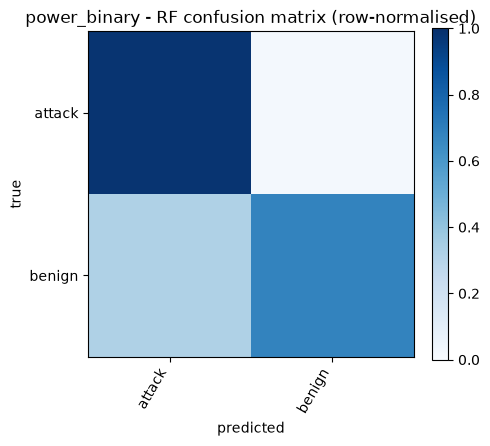

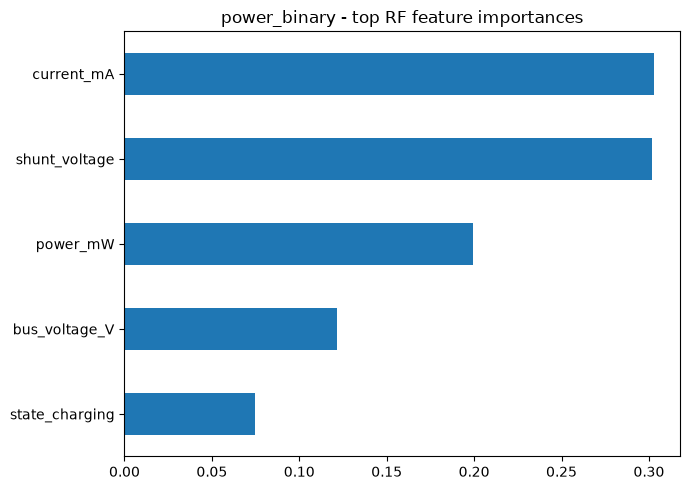


=== power_group | train 77,298 / test 38,000 | classes: ['DoS', 'host-attack', 'none', 'recon']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row
0,power_group,Dummy (majority),77298,38000,0.3026,0.1162,0.1406,0.05,0.0000
1,power_group,LogisticRegression,77298,38000,0.5255,0.4986,0.5110,1.07,0.0004
2,power_group,RandomForest,77298,38000,0.6526,0.6714,0.6480,4.22,0.0093


,precision,recall,f1-score,support
DoS,0.5551,0.4037,0.4675,11500.0000
host-attack,0.8326,0.7469,0.7874,11118.0000
none,0.7913,0.8111,0.8010,4721.0000
recon,0.5411,0.7525,0.6295,10661.0000
accuracy,0.6526,0.6526,0.6526,0.6526
macro avg,0.6800,0.6785,0.6714,38000.0000
weighted avg,0.6617,0.6526,0.6480,38000.0000


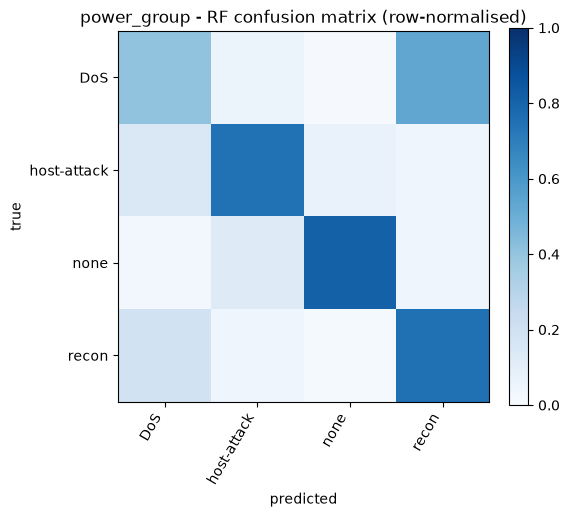

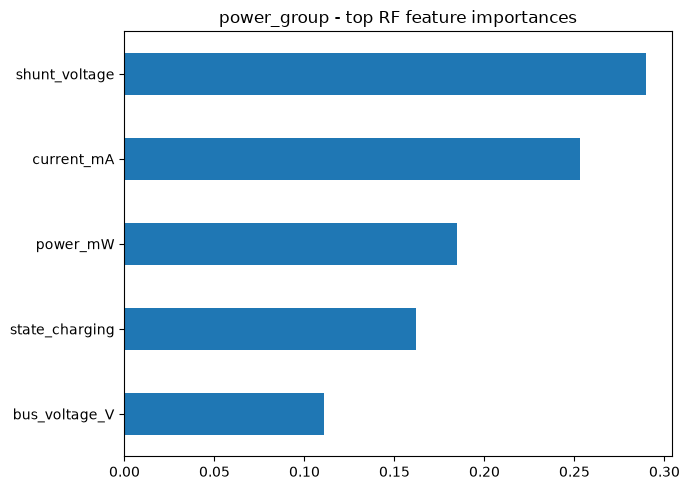

In [36]:
Xp = power[POWER_FEATS]
pb = run_experiment("power_binary", Xp, power["is_attack"].map({0: "benign", 1: "attack"}),
                    power["row_no"] // BLOCK_ROWS["power"], binary_positive="attack")
pg = run_experiment("power_group", Xp, power["group_norm"], power["row_no"] // BLOCK_ROWS["power"])


=== host_binary | train 5,568 / test 2,900 | classes: ['attack', 'benign']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row,ROC_AUC,PR_AUC
0,host_binary,Dummy (majority),5568,2900,0.7393,0.4251,0.6285,0.00,0.0000,0.5000,0.7393
1,host_binary,LogisticRegression,5568,2900,0.9959,0.9947,0.9959,0.53,0.0138,0.9992,0.9998
2,host_binary,RandomForest,5568,2900,0.9976,0.9969,0.9976,1.21,0.0586,0.9998,0.9999


,precision,recall,f1-score,support
attack,0.9991,0.9977,0.9984,2144.0000
benign,0.9934,0.9974,0.9954,756.0000
accuracy,0.9976,0.9976,0.9976,0.9976
macro avg,0.9962,0.9975,0.9969,2900.0000
weighted avg,0.9976,0.9976,0.9976,2900.0000


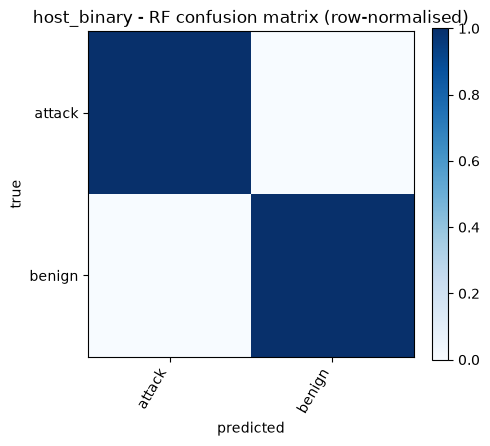

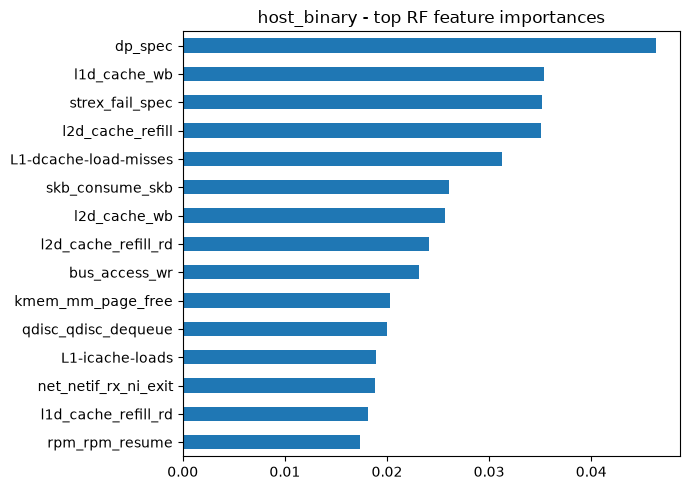


=== host_group | train 5,368 / test 3,100 | classes: ['DoS', 'host-attack', 'none', 'recon']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row
0,host_group,Dummy (majority),5368,3100,0.4606,0.1577,0.2905,0.01,0.0000
1,host_group,LogisticRegression,5368,3100,0.9910,0.9866,0.9909,0.98,0.0135
2,host_group,RandomForest,5368,3100,0.9910,0.9856,0.9909,1.30,0.0512


,precision,recall,f1-score,support
DoS,1.0000,0.9499,0.9743,499.000
host-attack,1.0000,1.0000,1.0000,1428.000
none,0.9840,1.0000,0.9920,801.000
recon,0.9609,0.9919,0.9762,372.000
accuracy,0.9910,0.9910,0.9910,0.991
macro avg,0.9862,0.9855,0.9856,3100.000
weighted avg,0.9912,0.9910,0.9909,3100.000


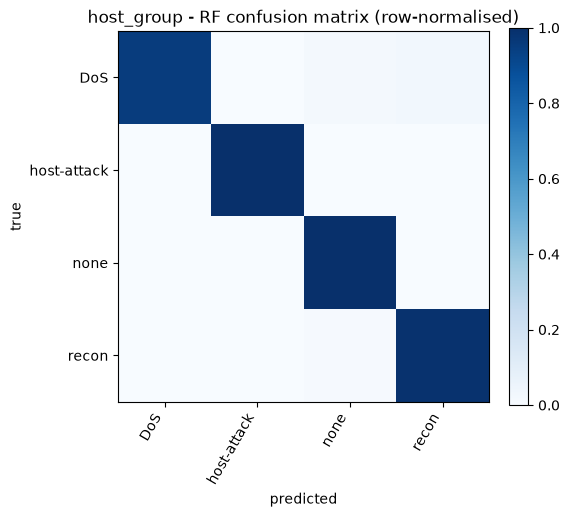

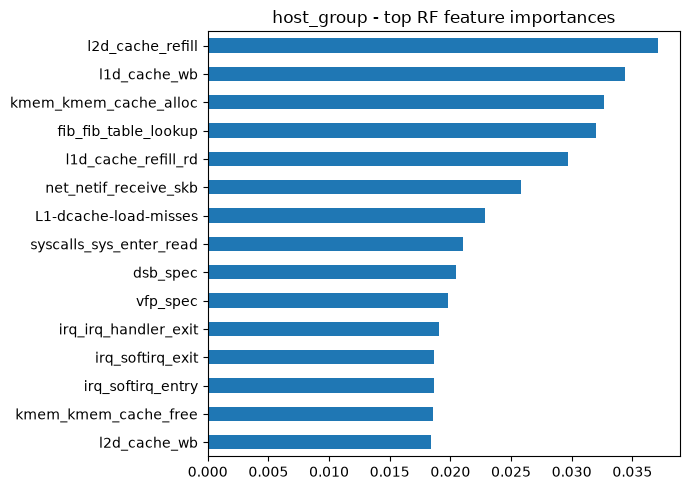

In [37]:
hb = run_experiment("host_binary", X_host, host["is_attack"].map({0: "benign", 1: "attack"}),
                    host["row_no"] // BLOCK_ROWS["host"], binary_positive="attack")
hg = run_experiment("host_group", X_host, host["group_norm"], host["row_no"] // BLOCK_ROWS["host"])

state_charging  0  1
attack_norm         
backdoor        1  1
benign          1  1
cryptojacking   1  1
syn-flood       1  0
syn-stealth     1  0
tcp-flood       1  0
vuln-scan       1  0 

state                Charging  idle
attack_norm                        
aggressive-scan             2     1
backdoor                    1     1
benign                      1     1
cryptojacking               1     1
icmp-flood                  1     1
icmp-fragmentation          2     1
os-fingerprinting           2     1
port-scan                   2     1
push-ack-flood              1     1
service-detection           2     1
syn-flood                   1     1
syn-stealth                 2     1
synonymous-ip-flood         1     1
tcp-flood                   1     1
udp-flood                   1     1
vuln-scan                   2     1 

   held-out recordings: [np.int64(1), np.int64(5), np.int64(8), np.int64(10)]

=== power_binary_rec | train 61,154 / test 54,144 | classes: ['attack', 'benign'

,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row,ROC_AUC,PR_AUC
0,power_binary_rec,Dummy (majority),61154,54144,0.863,0.4632,0.7996,0.03,0.0000,0.5000,0.8630
1,power_binary_rec,LogisticRegression,61154,54144,0.863,0.4632,0.7996,0.32,0.0003,0.7863,0.9535
2,power_binary_rec,RandomForest,61154,54144,0.863,0.4632,0.7996,2.70,0.0026,0.4929,0.8613


,precision,recall,f1-score,support
attack,0.8630,1.000,0.9265,46728.000
benign,0.0000,0.000,0.0000,7416.000
accuracy,0.8630,0.863,0.8630,0.863
macro avg,0.4315,0.500,0.4632,54144.000
weighted avg,0.7448,0.863,0.7996,54144.000


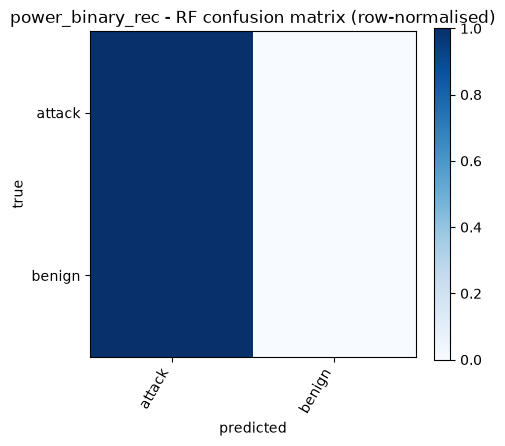

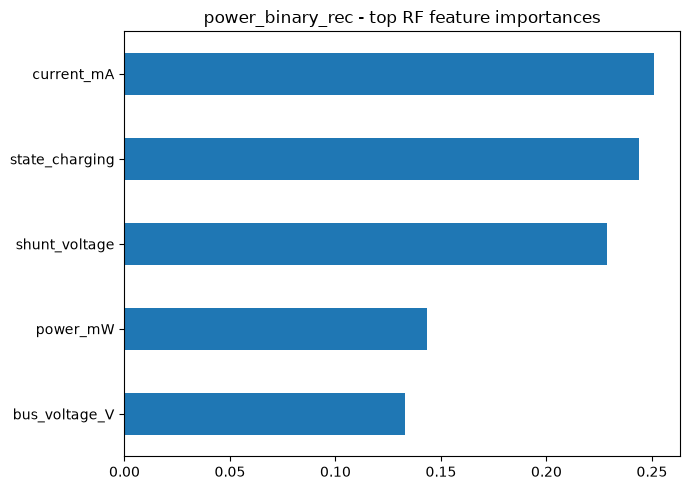

   held-out recordings: [np.int64(1), np.int64(5), np.int64(7), np.int64(10)]

=== power_group_rec | train 80,328 / test 34,970 | classes: ['DoS', 'host-attack', 'none', 'recon']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row
0,power_group_rec,Dummy (majority),80328,34970,0.2022,0.0841,0.0680,0.05,0.0000
1,power_group_rec,LogisticRegression,80328,34970,0.1079,0.0918,0.0860,0.74,0.0003
2,power_group_rec,RandomForest,80328,34970,0.1232,0.0986,0.0887,4.68,0.0082


,precision,recall,f1-score,support
DoS,0.0673,0.0385,0.0490,13517.0000
host-attack,0.0213,0.0372,0.0271,6965.0000
none,0.0000,0.0000,0.0000,7416.0000
recon,0.2338,0.4993,0.3185,7072.0000
accuracy,0.1232,0.1232,0.1232,0.1232
macro avg,0.0806,0.1437,0.0986,34970.0000
weighted avg,0.0775,0.1232,0.0887,34970.0000


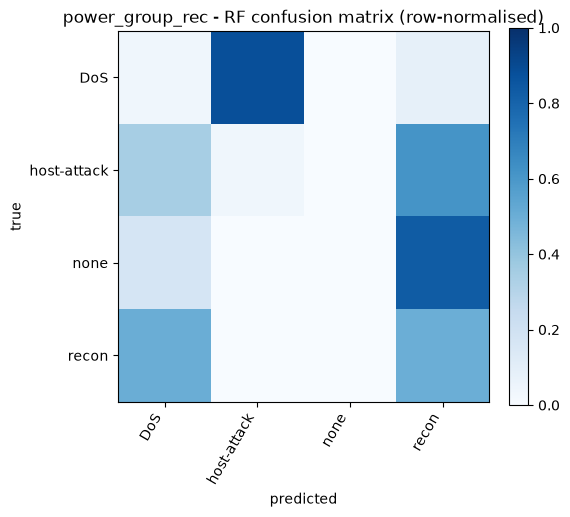

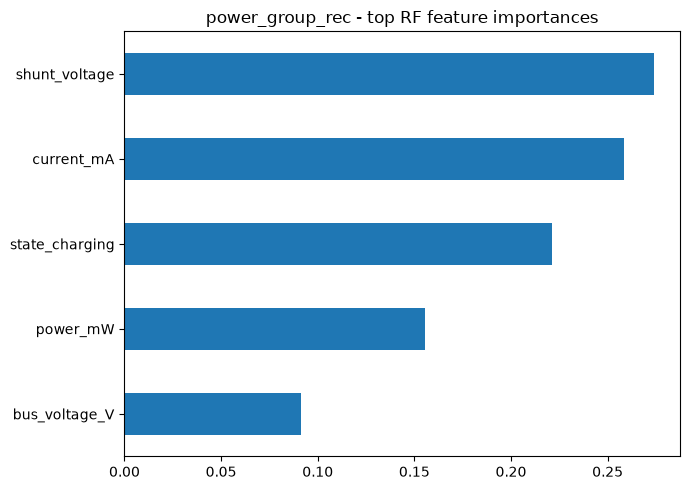

   held-out recordings: [np.int64(4), np.int64(5), np.int64(6), np.int64(9), np.int64(15), np.int64(21), np.int64(23), np.int64(26), np.int64(29), np.int64(32), np.int64(34), np.int64(38), np.int64(39)]

=== host_binary_rec | train 4,384 / test 4,084 | classes: ['attack', 'benign']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row,ROC_AUC,PR_AUC
0,host_binary_rec,Dummy (majority),4384,4084,0.7182,0.4180,0.6004,0.00,0.0000,0.5000,0.7182
1,host_binary_rec,LogisticRegression,4384,4084,0.1545,0.1338,0.1922,0.32,0.0123,0.2077,0.7724
2,host_binary_rec,RandomForest,4384,4084,0.7182,0.4180,0.6004,1.38,0.0360,0.0830,0.5325


,precision,recall,f1-score,support
attack,0.7182,1.0000,0.8360,2933.0000
benign,0.0000,0.0000,0.0000,1151.0000
accuracy,0.7182,0.7182,0.7182,0.7182
macro avg,0.3591,0.5000,0.4180,4084.0000
weighted avg,0.5158,0.7182,0.6004,4084.0000


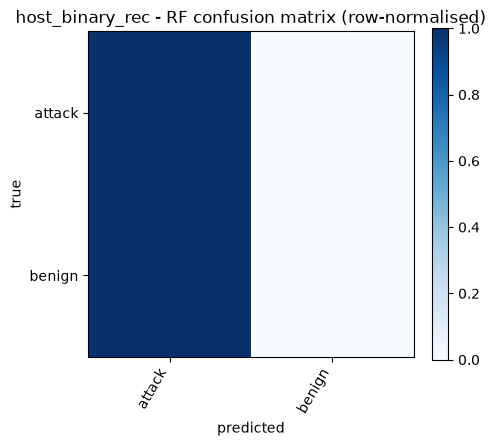

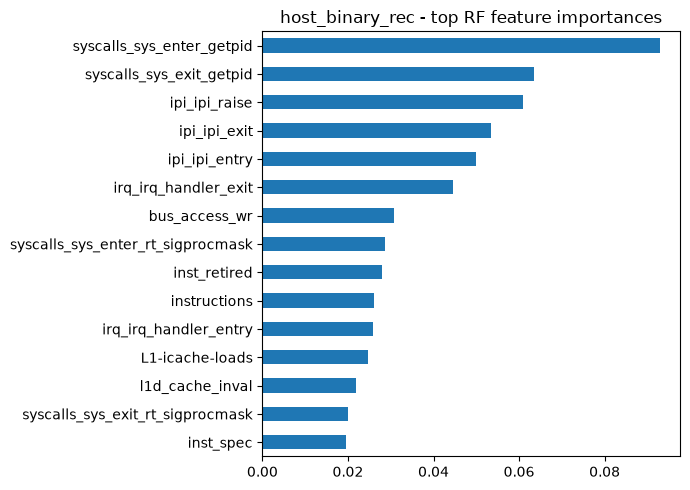

   held-out recordings: [np.int64(1), np.int64(4), np.int64(6), np.int64(17), np.int64(20), np.int64(23), np.int64(24), np.int64(27), np.int64(30), np.int64(31), np.int64(32), np.int64(34), np.int64(37)]

=== host_group_rec | train 5,474 / test 2,994 | classes: ['DoS', 'host-attack', 'none', 'recon']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row
0,host_group_rec,Dummy (majority),5474,2994,0.3844,0.1388,0.2135,0.00,0.0000
1,host_group_rec,LogisticRegression,5474,2994,0.2331,0.3126,0.1571,0.80,0.0109
2,host_group_rec,RandomForest,5474,2994,0.4272,0.4887,0.4154,1.36,0.0410


,precision,recall,f1-score,support
DoS,0.2207,0.9936,0.3612,311.0000
host-attack,1.0000,0.5161,0.6808,1151.0000
none,0.0000,0.0000,0.0000,1151.0000
recon,0.8488,0.9869,0.9126,381.0000
accuracy,0.4272,0.4272,0.4272,0.4272
macro avg,0.5174,0.6241,0.4887,2994.0000
weighted avg,0.5154,0.4272,0.4154,2994.0000


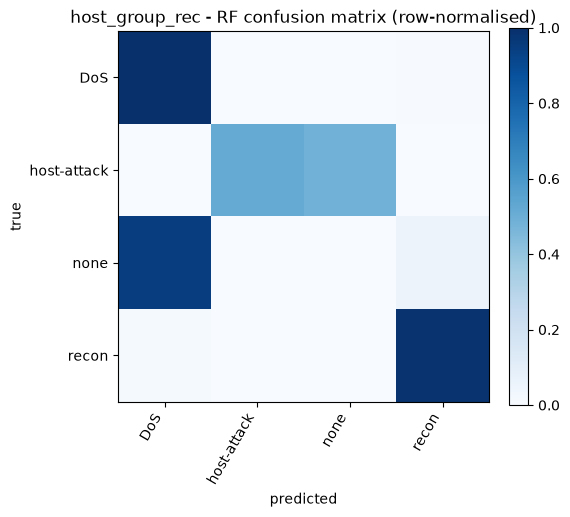

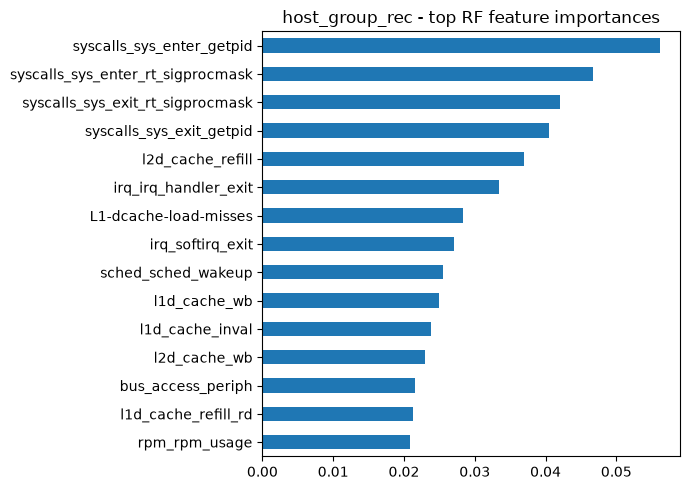

,rec_id,true,rows,acc,note
0,1,attack,13517,0.9974,
1,2,attack,21367,0.9879,
2,3,benign,6947,0.0000,
3,4,attack,8474,1.0000,
4,5,benign,7416,0.0000,
5,6,attack,3122,1.0000,
6,7,attack,7072,0.9900,
7,8,attack,26246,0.9865,
8,9,attack,14172,0.0593,
9,10,attack,6965,0.9648,


,experiment,model,n_test,accuracy,macro_F1,weighted_F1,per_rec_acc_mean,per_rec_acc_std,per_rec_acc_min
0,power_binary_LORO,RandomForest,115298,0.7514,0.429,0.7512,0.6986,0.4688,0.0


,rec_id,true,rows,acc,note
0,1,DoS,13517,0.0092,
1,2,DoS,21367,0.0053,
2,3,none,6947,0.0000,
3,4,host-attack,8474,1.0000,
4,5,none,7416,0.0000,
5,6,host-attack,3122,0.0061,
6,7,recon,7072,0.6646,
7,8,recon,26246,0.3957,
8,9,host-attack,14172,0.0476,
9,10,host-attack,6965,0.0072,


,experiment,model,n_test,accuracy,macro_F1,weighted_F1,per_rec_acc_mean,per_rec_acc_std,per_rec_acc_min
0,power_group_LORO,RandomForest,115298,0.2128,0.1688,0.1938,0.2136,0.3566,0.0


,rec_id,true,rows,acc,note
0,1,attack,1151,0.5847,
1,2,benign,1151,0.0000,
2,3,attack,642,1.0000,
3,4,benign,1151,0.0000,
4,5,attack,60,1.0000,
5,6,attack,67,1.0000,
6,7,attack,61,1.0000,
7,8,attack,62,1.0000,
8,9,attack,58,1.0000,
9,10,attack,62,1.0000,


,experiment,model,n_test,accuracy,macro_F1,weighted_F1,per_rec_acc_mean,per_rec_acc_std,per_rec_acc_min
0,host_binary_LORO,RandomForest,8468,0.6702,0.4013,0.5844,0.9325,0.2303,0.0


,rec_id,true,rows,acc,note
0,1,host-attack,1151,1.0000,
1,2,none,1151,0.0000,
2,3,host-attack,642,0.9984,
3,4,none,1151,0.0000,
4,5,recon,60,1.0000,
5,6,DoS,67,0.9851,
6,7,DoS,61,0.9836,
7,8,recon,62,0.9839,
8,9,recon,58,1.0000,
9,10,DoS,62,1.0000,


,experiment,model,n_test,accuracy,macro_F1,weighted_F1,per_rec_acc_mean,per_rec_acc_std,per_rec_acc_min
0,host_group_LORO,RandomForest,8468,0.7228,0.5657,0.6378,0.9301,0.2234,0.0


In [38]:
# --- sanity check: which states does each recording cover? (tests the benign-per-state suspicion) ---
print(power.groupby(["attack_norm", "state_charging"])["rec_id"].nunique().unstack(fill_value=0), "\n")
print(host.groupby(["attack_norm", "state"])["rec_id"].nunique().unstack(fill_value=0), "\n")

yb_p = power["is_attack"].map({0: "benign", 1: "attack"})
yb_h = host["is_attack"].map({0: "benign", 1: "attack"})
blk_p = power["row_no"] // BLOCK_ROWS["power"]
blk_h = host["row_no"]  // BLOCK_ROWS["host"]

# single held-out-recording split (seeded)
pb_rec = run_experiment("power_binary_rec", power[POWER_FEATS], yb_p, blk_p, binary_positive="attack", rec=power["rec_id"])
pg_rec = run_experiment("power_group_rec",  power[POWER_FEATS], power["group_norm"], blk_p, rec=power["rec_id"])
hb_rec = run_experiment("host_binary_rec",  X_host, yb_h, blk_h, binary_positive="attack", rec=host["rec_id"])
hg_rec = run_experiment("host_group_rec",   X_host, host["group_norm"], blk_h, rec=host["rec_id"])

# leave-one-recording-out (the numbers to trust: mean, std, worst case)
loro_power_bin = loro_experiment("power_binary_LORO", power[POWER_FEATS], yb_p, power["rec_id"])
loro_power_grp = loro_experiment("power_group_LORO",  power[POWER_FEATS], power["group_norm"], power["rec_id"])
loro_host_bin  = loro_experiment("host_binary_LORO",  X_host, yb_h, host["rec_id"])
loro_host_grp  = loro_experiment("host_group_LORO",   X_host, host["group_norm"], host["rec_id"])

In [39]:
net_results = {}
for key in net:
    df, feats = net[key]["df"], net[key]["feats"]
    keep_classes = df["attack_norm"].value_counts()[lambda s: s >= MIN_CLASS_SAMPLES].index
    small = sorted(set(df["attack_norm"]) - set(keep_classes))
    if small: log(f"{key}: classes with <{MIN_CLASS_SAMPLES} sampled rows not modelled: {small}")
    d = df[df["attack_norm"].isin(keep_classes)].reset_index(drop=True)
    X = d[feats].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    net_results[key] = run_experiment(f"{key}_attack_type", X, d["attack_norm"], d["block"])

# EVSE-A benign vs attack, using the dedicated benign CSVs (EVSE-B has NO benign network files at all)
if benign_A is not None and len(benign_A) >= MIN_CLASS_SAMPLES:
    atk = net["netA"]["df"]; atk = atk[atk["attack_norm"] != "benign"]
    both = pd.concat([benign_A, atk], ignore_index=True)
    feats = [f for f in net["netA"]["feats"] if f in benign_A.columns]
    X = both[feats].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    y = np.where(both["attack_norm"] == "benign", "benign", "attack")
    net_results["netA_binary"] = run_experiment("netA_binary", X, y, both["block"], binary_positive="attack")
    print("CAUTION: benign and attack flows come from different capture files -> a model can partly learn the capture "
          "session instead of behaviour. Report this limitation.")
else:
    print("No usable EVSE-A benign flows -> network binary detection skipped.")

No usable EVSE-A benign flows -> network binary detection skipped.


## 9. Separate anomaly experiment (Isolation Forest, trained on BENIGN power only)
An anomaly score is not proof of an attack - this is reported as its own experiment.

In [40]:
tr, te = pb["tr"], pb["te"]
Xtr_b = power.iloc[tr].query("is_attack == 0")[POWER_FEATS]
scaler = StandardScaler().fit(Xtr_b)
iso = IsolationForest(n_estimators=200, contamination="auto", random_state=SEED).fit(scaler.transform(Xtr_b))
score_te = -iso.score_samples(scaler.transform(power.iloc[te][POWER_FEATS]))      # higher = more anomalous
y_te = power.iloc[te]["is_attack"].values
thr = np.percentile(-iso.score_samples(scaler.transform(Xtr_b)), 95)             # 95th pct of benign-train scores
pred = (score_te > thr).astype(int)
tp = int(((pred == 1) & (y_te == 1)).sum()); fp = int(((pred == 1) & (y_te == 0)).sum())
fn = int(((pred == 0) & (y_te == 1)).sum()); tn = int(((pred == 0) & (y_te == 0)).sum())
iso_row = {"experiment": "power_anomaly", "model": "IsolationForest(benign-only)", "n_train": len(Xtr_b), "n_test": len(te),
           "ROC_AUC": roc_auc_score(y_te, score_te), "PR_AUC": average_precision_score(y_te, score_te),
           "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1), "false_positive_rate": fp / max(fp + tn, 1)}
SUMMARY.append(iso_row); display(pd.DataFrame([iso_row]).round(4))
print(f"Threshold = 95th percentile of benign-train scores ({thr:.4f}); a threshold choice you must justify to the panel.")

,experiment,model,n_train,n_test,ROC_AUC,PR_AUC,precision,recall,false_positive_rate
0,power_anomaly,IsolationForest(benign-only),9721,38000,0.7061,0.9459,0.97,0.359,0.0797


Threshold = 95th percentile of benign-train scores (0.5823); a threshold choice you must justify to the panel.


## 10. Sample structured alerts (the hand-off to the agentic layer)
Fields clearly separate **dataset observation**, **model prediction**, and **ground truth (evaluation only)**.

In [41]:
rf, te = pb["rf"], pb["te"]
Xte = power.iloc[te]
proba = rf.predict_proba(Xte[POWER_FEATS])[:, list(rf.classes_).index("attack")]
cand_atk = np.where((Xte["is_attack"].values == 1) & (proba > 0.5))[0][:3]
cand_ben = np.where(Xte["is_attack"].values == 0)[0][:2]
top = pb["importance"].head(3)
alerts = []
for i in list(cand_atk) + list(cand_ben):
    r = Xte.iloc[i]
    alerts.append({
        "alert_id": f"ALERT-{int(r['row_no']):06d}",
        "observation": {"source": "power", "row_ref": int(r["row_no"]), "time": str(r["time"]),
                        "features": {f: float(r[f]) for f in POWER_FEATS}},
        "model_prediction": {"model": "RandomForest(power_binary)", "label": "attack" if proba[i] > 0.5 else "benign",
                             "confidence": round(float(proba[i]), 4)},
        "explanation_attribution": [{"feature": f, "global_importance": round(float(v), 4), "value": float(r[f])}
                                    for f, v in top.items()],
        "ground_truth_for_evaluation_only": {"attack": r["attack_norm"], "group": r["group_norm"]},
        "status": "needs_investigation" if proba[i] > 0.5 else "no_action",
        "note": "Feature attribution is not causal proof. Agent must retrieve evidence before claiming an incident.",
    })
(RESULTS / "alerts_demo.json").write_text(json.dumps(alerts, indent=2))
print(json.dumps(alerts[0], indent=2))

{
  "alert_id": "ALERT-004000",
  "observation": {
    "source": "power",
    "row_ref": 4000,
    "time": "12/25/2023 23:44",
    "features": {
      "shunt_voltage": 918.0,
      "bus_voltage_V": 5.165,
      "current_mA": 964.0,
      "power_mW": 4820.0,
      "state_charging": 0.0
    }
  },
  "model_prediction": {
    "model": "RandomForest(power_binary)",
    "label": "attack",
    "confidence": 1.0
  },
  "explanation_attribution": [
    {
      "feature": "current_mA",
      "global_importance": 0.3026,
      "value": 964.0
    },
    {
      "feature": "shunt_voltage",
      "global_importance": 0.3019,
      "value": 918.0
    },
    {
      "feature": "power_mW",
      "global_importance": 0.1992,
      "value": 4820.0
    }
  ],
  "ground_truth_for_evaluation_only": {
    "attack": "syn-flood",
    "group": "DoS"
  },
  "status": "needs_investigation",
  "note": "Feature attribution is not causal proof. Agent must retrieve evidence before claiming an incident."
}


## 11. Optional: cross-device check (train on EVSE-A, test on EVSE-B, shared attack types only)
A stronger generalisation test than a within-device split. Expect lower scores; report them honestly.

In [42]:
if "netA" in net and "netB" in net:
    dA, fA = net["netA"]["df"], net["netA"]["feats"]; dB, fB = net["netB"]["df"], net["netB"]["feats"]
    shared = sorted(set(dA.attack_norm) & set(dB.attack_norm))
    shared = [c for c in shared if (dA.attack_norm == c).sum() >= MIN_CLASS_SAMPLES and (dB.attack_norm == c).sum() >= MIN_CLASS_SAMPLES]
    feats = [f for f in fA if f in fB]
    a = dA[dA.attack_norm.isin(shared)]; b = dB[dB.attack_norm.isin(shared)]
    conv = lambda d: d[feats].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    m = make_models()["RandomForest"].fit(conv(a), a.attack_norm)
    p = m.predict(conv(b))
    row = {"experiment": "cross_device_A_to_B", "model": "RandomForest", "n_train": len(a), "n_test": len(b),
           "accuracy": accuracy_score(b.attack_norm, p), "macro_F1": f1_score(b.attack_norm, p, average="macro", zero_division=0),
           "weighted_F1": f1_score(b.attack_norm, p, average="weighted", zero_division=0)}
    SUMMARY.append(row); display(pd.DataFrame([row]).round(4)); print("Shared classes:", shared)

## 12. Robustness checks (reuse the data already in memory - run after section 11)
First results raised four questions; each check below answers one:
1. Is network accuracy leaning on `dst_port` (an artifact of how the attacks were scripted)?
2. Are nmap scan sub-types separable at all, or only DoS-vs-recon at group level?
3. Does power detection improve with short time-window features (attacks are temporal)?
4. Do host / power models still work when trained on one state (idle) and tested on the other (charging)?
5. Is the near-perfect host score carried by the backdoor block that came from the stacked second file?

In [43]:
def net_frame(key):
    df, feats = net[key]["df"], net[key]["feats"]
    keep = df["attack_norm"].value_counts()[lambda s: s >= MIN_CLASS_SAMPLES].index
    d = df[df["attack_norm"].isin(keep)].reset_index(drop=True)
    X = d[feats].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    return d, X

for key in net:
    d, X = net_frame(key)
    X_np = X.drop(columns=["dst_port"], errors="ignore")
    run_experiment(f"{key}_attack_type_noport", X_np, d["attack_norm"], d["block"])   # check 1
    run_experiment(f"{key}_group_noport", X_np, d["group_norm"], d["block"])          # check 2 (no dst_port)
    run_experiment(f"{key}_group_withport", X, d["group_norm"], d["block"])           # check 2 (with dst_port)

### 12c. Power with short rolling-window features (causal: each row only sees the past 10 / 30 seconds)

Window features added: ['current_mA_mean10', 'current_mA_std10', 'power_mW_mean10', 'power_mW_std10', 'current_mA_mean30', 'current_mA_std30', 'power_mW_mean30', 'power_mW_std30']
   held-out recordings: [np.int64(1), np.int64(5), np.int64(8), np.int64(10)]

=== power_binary_windowed_rec | train 61,154 / test 54,144 | classes: ['attack', 'benign']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row,ROC_AUC,PR_AUC
0,power_binary_windowed_rec,Dummy (majority),61154,54144,0.8630,0.4632,0.7996,0.04,0.0000,0.5000,0.8630
1,power_binary_windowed_rec,LogisticRegression,61154,54144,0.8630,0.4632,0.7996,0.70,0.0007,0.7859,0.9605
2,power_binary_windowed_rec,RandomForest,61154,54144,0.8629,0.4632,0.7995,4.70,0.0040,0.4401,0.8482


,precision,recall,f1-score,support
attack,0.8630,0.9998,0.9264,46728.0000
benign,0.0000,0.0000,0.0000,7416.0000
accuracy,0.8629,0.8629,0.8629,0.8629
macro avg,0.4315,0.4999,0.4632,54144.0000
weighted avg,0.7448,0.8629,0.7995,54144.0000


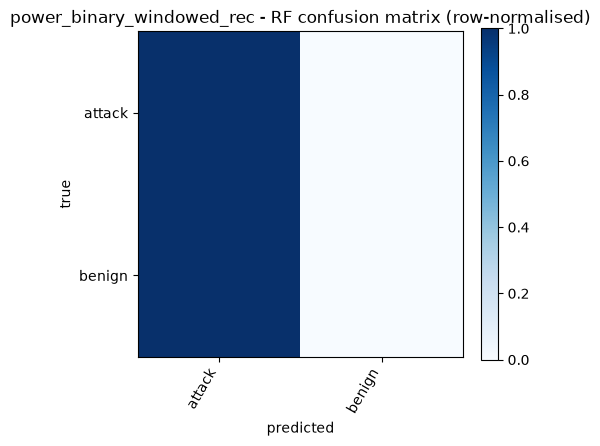

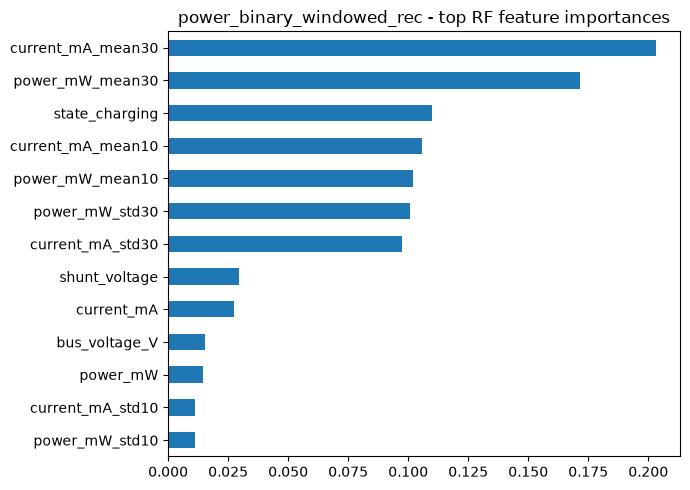

   held-out recordings: [np.int64(1), np.int64(5), np.int64(7), np.int64(10)]

=== power_group_windowed_rec | train 80,328 / test 34,970 | classes: ['DoS', 'host-attack', 'none', 'recon']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row
0,power_group_windowed_rec,Dummy (majority),80328,34970,0.2022,0.0841,0.0680,0.05,0.0000
1,power_group_windowed_rec,LogisticRegression,80328,34970,0.0905,0.0831,0.0672,2.21,0.0006
2,power_group_windowed_rec,RandomForest,80328,34970,0.1409,0.1001,0.0809,14.11,0.0086


,precision,recall,f1-score,support
DoS,0.0000,0.0000,0.0000,13517.0000
host-attack,0.0074,0.0142,0.0097,6965.0000
none,0.0000,0.0000,0.0000,7416.0000
recon,0.2737,0.6826,0.3907,7072.0000
accuracy,0.1409,0.1409,0.1409,0.1409
macro avg,0.0703,0.1742,0.1001,34970.0000
weighted avg,0.0568,0.1409,0.0809,34970.0000


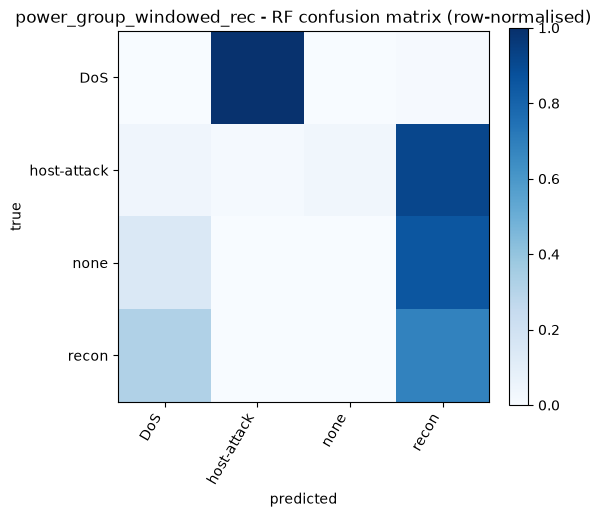

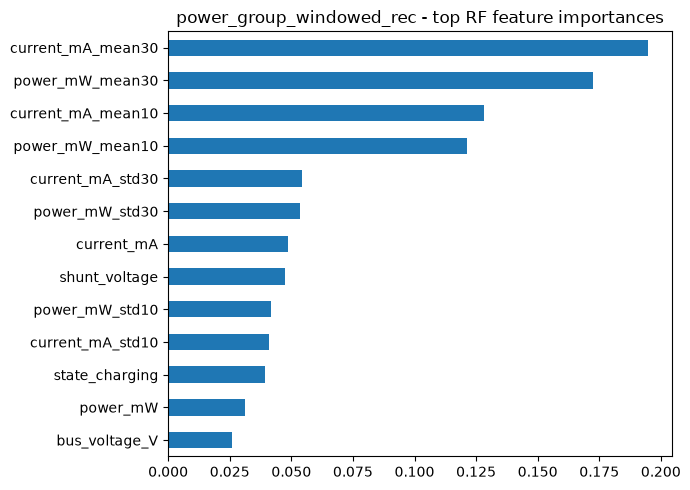

,rec_id,true,rows,acc,note
0,1,attack,13517,1.0000,
1,2,attack,21367,0.9989,
2,3,benign,6947,0.0000,
3,4,attack,8474,1.0000,
4,5,benign,7416,0.0000,
5,6,attack,3122,1.0000,
6,7,attack,7072,0.9999,
7,8,attack,26246,0.9987,
8,9,attack,14172,0.1414,
9,10,attack,6965,0.9980,


,experiment,model,n_test,accuracy,macro_F1,weighted_F1,per_rec_acc_mean,per_rec_acc_std,per_rec_acc_min
0,power_binary_windowed_LORO,RandomForest,115298,0.7693,0.4348,0.7613,0.7137,0.4616,0.0


,rec_id,true,rows,acc,note
0,1,DoS,13517,0.0000,
1,2,DoS,21367,0.0000,
2,3,none,6947,0.0000,
3,4,host-attack,8474,0.9173,
4,5,none,7416,0.0000,
5,6,host-attack,3122,0.0000,
6,7,recon,7072,0.6431,
7,8,recon,26246,0.0290,
8,9,host-attack,14172,0.0000,
9,10,host-attack,6965,0.0000,


,experiment,model,n_test,accuracy,macro_F1,weighted_F1,per_rec_acc_mean,per_rec_acc_std,per_rec_acc_min
0,power_group_windowed_LORO,RandomForest,115298,0.1135,0.102,0.1166,0.1589,0.3339,0.0


,rec_id,true,rows,acc,note
0,1,DoS,13517,0.000000,
1,2,DoS,21367,0.000000,
2,3,none,6947,0.000000,
3,4,host-attack,8474,0.917276,
4,5,none,7416,0.000000,
5,6,host-attack,3122,0.000000,
6,7,recon,7072,0.643100,
7,8,recon,26246,0.028957,
8,9,host-attack,14172,0.000000,
9,10,host-attack,6965,0.000000,


In [44]:
Xw = power[POWER_FEATS].copy()
for w in (10, 30):
    for col in ("current_mA", "power_mW"):
        g = power.groupby("rec_id")[col]
        Xw[f"{col}_mean{w}"] = g.transform(lambda s: s.rolling(w, min_periods=1).mean())
        Xw[f"{col}_std{w}"]  = g.transform(lambda s: s.rolling(w, min_periods=1).std()).fillna(0)
print("Window features added:", [c for c in Xw.columns if c not in POWER_FEATS])

run_experiment("power_binary_windowed_rec", Xw, yb_p, blk_p, binary_positive="attack", rec=power["rec_id"])
run_experiment("power_group_windowed_rec",  Xw, power["group_norm"], blk_p, rec=power["rec_id"])
loro_experiment("power_binary_windowed_LORO", Xw, yb_p, power["rec_id"])
loro_experiment("power_group_windowed_LORO",  Xw, power["group_norm"], power["rec_id"])

### 12d. Cross-state generalisation (train idle -> test charging, and the reverse)

In [45]:
def cross_state(tag, X, y, state):
    X = X.reset_index(drop=True); y = pd.Series(np.asarray(y)).astype(str); state = pd.Series(np.asarray(state)).astype(str)
    print(f"\n{tag}: state counts ->", state.value_counts().to_dict())
    for a, b in [("idle", "charging"), ("charging", "idle")]:
        tr, te = (state == a).values, (state == b).values
        if tr.sum() < 200 or te.sum() < 200:
            print(f"  skipped {a}->{b}: not enough rows in both states"); continue
        m = make_models()["RandomForest"].fit(X[tr], y[tr]); p = m.predict(X[te])
        rep = classification_report(y[te], p, output_dict=True, zero_division=0)
        row = {"experiment": f"{tag}_{a}_to_{b}", "model": "RandomForest", "n_train": int(tr.sum()), "n_test": int(te.sum()),
               "accuracy": accuracy_score(y[te], p), "macro_F1": f1_score(y[te], p, average="macro", zero_division=0),
               "weighted_F1": f1_score(y[te], p, average="weighted", zero_division=0)}
        row.update({f"recall_{c}": rep[c]["recall"] for c in rep if c not in ("accuracy", "macro avg", "weighted avg")})
        SUMMARY.append(row); display(pd.DataFrame([row]).round(4))

pstate = np.where(power["state_charging"] == 1, "charging", "idle")
cross_state("power_binary", power[POWER_FEATS], power["is_attack"].map({0: "benign", 1: "attack"}), pstate)
cross_state("power_group", power[POWER_FEATS], power["group_norm"], pstate)
hs = host["state"].astype("string").str.strip().str.lower()
hstate = np.where(hs.str.contains("charg", na=False), "charging", np.where(hs.str.contains("idle", na=False), "idle", "unknown"))
cross_state("host_binary", X_host, host["is_attack"].map({0: "benign", 1: "attack"}), hstate)
cross_state("host_group", X_host, host["group_norm"], hstate)


power_binary: state counts -> {'idle': 85705, 'charging': 29593}


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,recall_attack,recall_benign
0,power_binary_idle_to_charging,RandomForest,85705,29593,0.765,0.449,0.6704,0.9947,0.0164


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,recall_attack,recall_benign
0,power_binary_charging_to_idle,RandomForest,29593,85705,0.3316,0.3039,0.4186,0.2905,0.7646



power_group: state counts -> {'idle': 85705, 'charging': 29593}


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,recall_DoS,recall_host-attack,recall_none,recall_recon
0,power_group_idle_to_charging,RandomForest,85705,29593,0.1911,0.1081,0.2903,0.0,0.2368,0.042,0.0


...

,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,recall_attack,recall_benign
0,host_binary_idle_to_charging,RandomForest,3733,4735,0.7569,0.4308,0.6522,1.0,0.0


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,recall_attack,recall_benign
0,host_binary_charging_to_idle,RandomForest,4735,3733,0.6917,0.4089,0.5656,1.0,0.0



host_group: state counts -> {'charging': 4735, 'idle': 3733}


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,recall_DoS,recall_host-attack,recall_none,recall_recon
0,host_group_idle_to_charging,RandomForest,3733,4735,0.7339,0.5755,0.6723,0.98,1.0,0.0,0.8734


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,recall_DoS,recall_host-attack,recall_none,recall_recon
0,host_group_charging_to_idle,RandomForest,4735,3733,0.6844,0.5874,0.6278,0.939,0.9994,0.0,1.0


### 12e. Host without the backdoor block (the rows rebuilt from the stacked second file)

Host rows without backdoor block: 6,166 (removed 2,302)

=== host_binary_no_backdoor | train 4,150 / test 2,016 | classes: ['attack', 'benign']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row,ROC_AUC,PR_AUC
0,host_binary_no_backdoor,Dummy (majority),4150,2016,0.6027,0.3760,0.4533,0.01,0.0005,0.5000,0.6027
1,host_binary_no_backdoor,LogisticRegression,4150,2016,0.9945,0.9943,0.9945,0.48,0.0144,0.9987,0.9993
2,host_binary_no_backdoor,RandomForest,4150,2016,0.9955,0.9953,0.9955,1.56,0.0740,0.9990,0.9994


,precision,recall,f1-score,support
attack,0.9992,0.9934,0.9963,1215.0000
benign,0.9901,0.9988,0.9944,801.0000
accuracy,0.9955,0.9955,0.9955,0.9955
macro avg,0.9946,0.9961,0.9953,2016.0000
weighted avg,0.9956,0.9955,0.9955,2016.0000


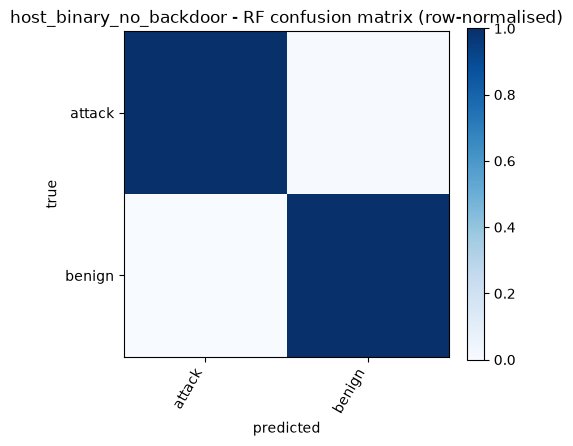

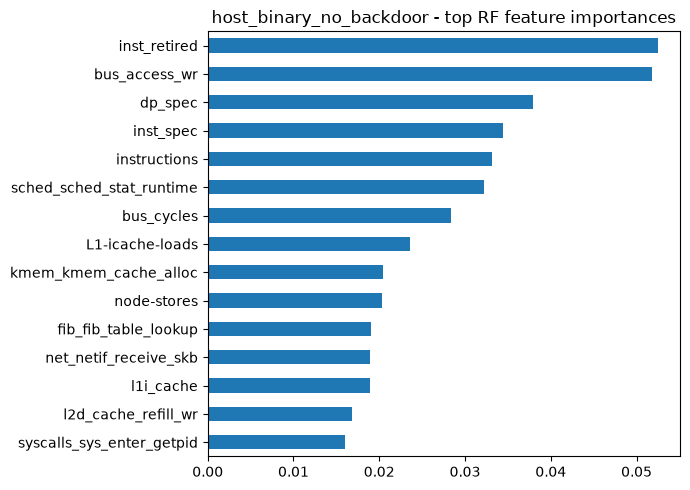


=== host_group_no_backdoor | train 3,766 / test 2,400 | classes: ['DoS', 'host-attack', 'none', 'recon']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row
0,host_group_no_backdoor,Dummy (majority),3766,2400,0.2929,0.1133,0.1327,0.01,0.0000
1,host_group_no_backdoor,LogisticRegression,3766,2400,0.9892,0.9881,0.9891,1.02,0.0135
2,host_group_no_backdoor,RandomForest,3766,2400,0.9879,0.9865,0.9879,1.40,0.0707


,precision,recall,f1-score,support
DoS,1.0000,0.9569,0.9780,534.0000
host-attack,1.0000,1.0000,1.0000,692.0000
none,0.9859,0.9957,0.9908,703.0000
recon,0.9610,0.9936,0.9770,471.0000
accuracy,0.9879,0.9879,0.9879,0.9879
macro avg,0.9867,0.9866,0.9865,2400.0000
weighted avg,0.9882,0.9879,0.9879,2400.0000


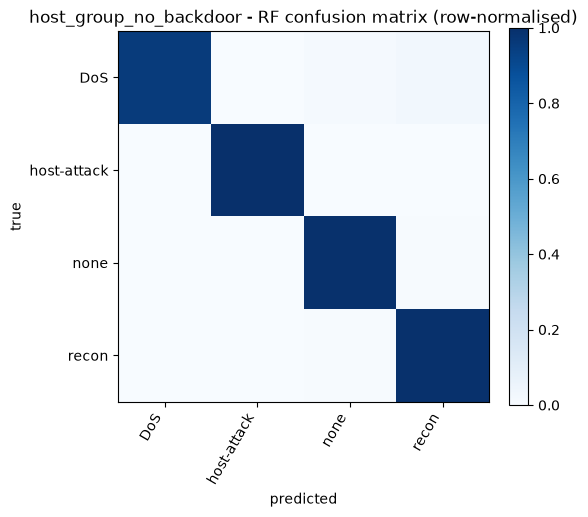

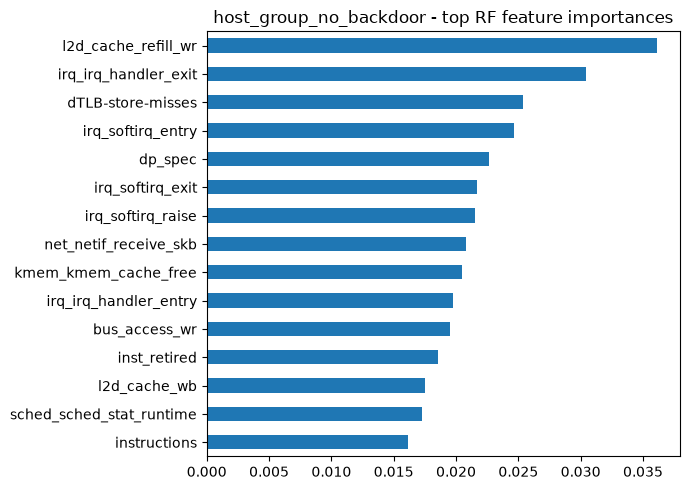

   held-out recordings: [np.int64(4), np.int64(5), np.int64(6), np.int64(9), np.int64(14), np.int64(15), np.int64(20), np.int64(22), np.int64(24), np.int64(27), np.int64(32), np.int64(36), np.int64(37)]

=== host_binary_no_backdoor_rec | train 4,285 / test 1,881 | classes: ['attack', 'benign']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row,ROC_AUC,PR_AUC
0,host_binary_no_backdoor_rec,Dummy (majority),4285,1881,0.3881,0.2796,0.217,0.01,0.0000,0.5000,0.3881
1,host_binary_no_backdoor_rec,LogisticRegression,4285,1881,0.3881,0.2796,0.217,0.33,0.0095,0.9761,0.9808
2,host_binary_no_backdoor_rec,RandomForest,4285,1881,0.3881,0.2796,0.217,1.38,0.0677,0.3752,0.3294


,precision,recall,f1-score,support
attack,0.3881,1.0000,0.5592,730.0000
benign,0.0000,0.0000,0.0000,1151.0000
accuracy,0.3881,0.3881,0.3881,0.3881
macro avg,0.1940,0.5000,0.2796,1881.0000
weighted avg,0.1506,0.3881,0.2170,1881.0000


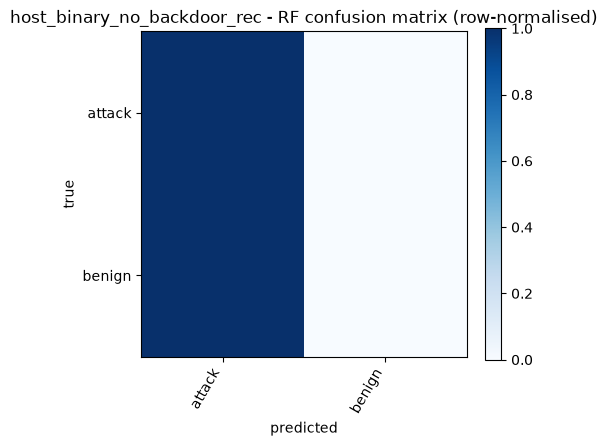

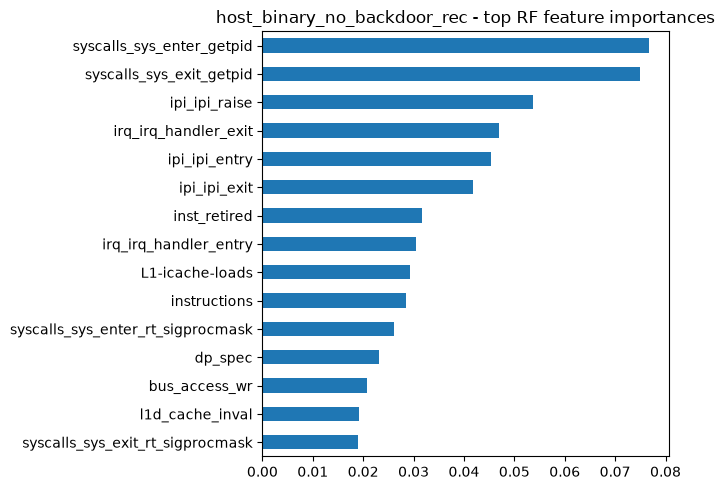

   held-out recordings: [np.int64(1), np.int64(4), np.int64(6), np.int64(17), np.int64(20), np.int64(23), np.int64(24), np.int64(27), np.int64(30), np.int64(31), np.int64(32), np.int64(34), np.int64(37)]

=== host_group_no_backdoor_rec | train 3,172 / test 2,994 | classes: ['DoS', 'host-attack', 'none', 'recon']


,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row
0,host_group_no_backdoor_rec,Dummy (majority),3172,2994,0.3844,0.1388,0.2135,0.00,0.0000
1,host_group_no_backdoor_rec,LogisticRegression,3172,2994,0.6005,0.5366,0.5225,1.43,0.0094
2,host_group_no_backdoor_rec,RandomForest,3172,2994,0.6129,0.5676,0.5377,1.38,0.0390


,precision,recall,f1-score,support
DoS,0.2209,0.9936,0.3614,311.0000
host-attack,1.0000,1.0000,1.0000,1151.0000
none,0.0000,0.0000,0.0000,1151.0000
recon,0.8446,0.9843,0.9091,381.0000
accuracy,0.6129,0.6129,0.6129,0.6129
macro avg,0.5164,0.7445,0.5676,2994.0000
weighted avg,0.5149,0.6129,0.5377,2994.0000


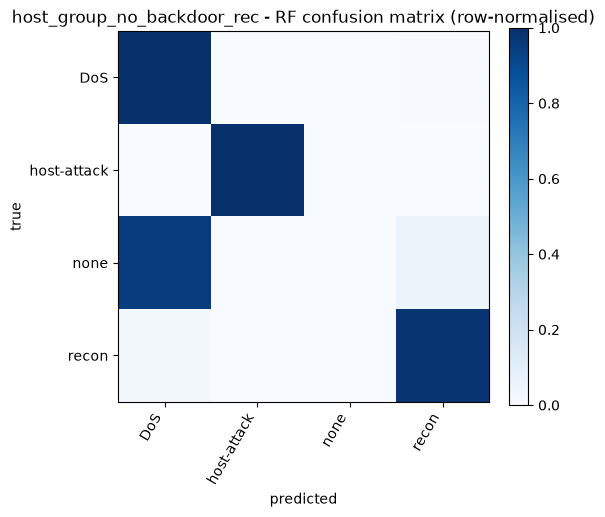

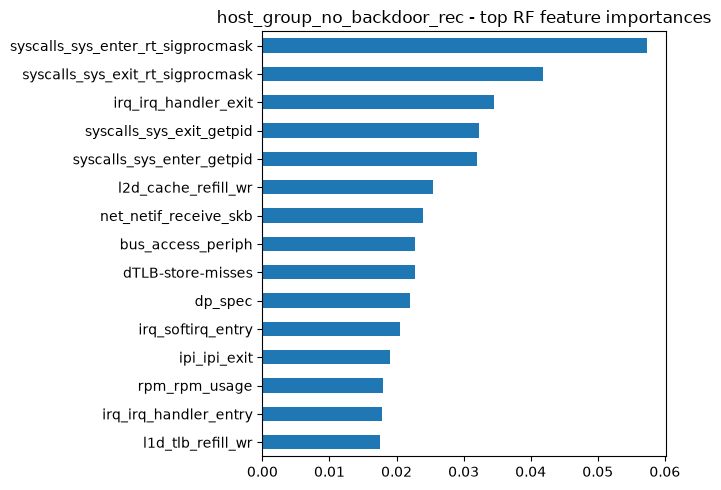

In [46]:
keep_rows = (~host["block2"]).values
Xh = X_host[keep_rows].reset_index(drop=True); hh = host[keep_rows].reset_index(drop=True)
print(f"Host rows without backdoor block: {len(hh):,} (removed {int((~keep_rows).sum()):,})")
run_experiment("host_binary_no_backdoor", Xh, hh["is_attack"].map({0: "benign", 1: "attack"}),
               hh["row_no"] // BLOCK_ROWS["host"], binary_positive="attack")
_ = run_experiment("host_group_no_backdoor", Xh, hh["group_norm"], hh["row_no"] // BLOCK_ROWS["host"])
run_experiment("host_binary_no_backdoor_rec", Xh, hh["is_attack"].map({0: "benign", 1: "attack"}),
               hh["row_no"] // BLOCK_ROWS["host"], binary_positive="attack", rec=hh["rec_id"])
_ = run_experiment("host_group_no_backdoor_rec", Xh, hh["group_norm"],
                   hh["row_no"] // BLOCK_ROWS["host"], rec=hh["rec_id"])

### 12f. Side-by-side: baseline vs robustness variants (Random Forest)

In [47]:
s = pd.DataFrame(SUMMARY)
s = s[s["model"] == "RandomForest"]
cols = [c for c in ["experiment", "n_test", "accuracy", "macro_F1", "weighted_F1",
                    "per_rec_acc_mean", "per_rec_acc_std", "per_rec_acc_min"] if c in s.columns]
display(s[cols].round(4).reset_index(drop=True))

,experiment,n_test,accuracy,macro_F1,weighted_F1,per_rec_acc_mean,per_rec_acc_std,per_rec_acc_min
0,power_binary,38000,0.9451,0.8599,0.9425,NaN,NaN,NaN
1,power_group,38000,0.6526,0.6714,0.6480,NaN,NaN,NaN
2,host_binary,2900,0.9976,0.9969,0.9976,NaN,NaN,NaN
3,host_group,3100,0.9910,0.9856,0.9909,NaN,NaN,NaN
4,power_binary_rec,54144,0.8630,0.4632,0.7996,NaN,NaN,NaN
5,power_group_rec,34970,0.1232,0.0986,0.0887,NaN,NaN,NaN
6,host_binary_rec,4084,0.7182,0.4180,0.6004,NaN,NaN,NaN
7,host_group_rec,2994,0.4272,0.4887,0.4154,NaN,NaN,NaN
8,power_binary_LORO,115298,0.7514,0.4290,0.7512,0.6986,0.4688,0.0
9,power_group_LORO,115298,0.2128,0.1688,0.1938,0.2136,0.3566,0.0


## 13. Save everything for the mentor / report

In [48]:
summary_df = pd.DataFrame(SUMMARY).round(4)
summary_df.to_csv(RESULTS / "metrics_summary.csv", index=False)
pd.Series(CLEANING_LOG, name="cleaning_decision").to_csv(RESULTS / "cleaning_log.csv", index=False)
display(summary_df)
print("\nSaved to:", RESULTS.resolve())
print("Files:", sorted(p.name for p in RESULTS.iterdir()))

,experiment,model,n_train,n_test,accuracy,macro_F1,weighted_F1,train_s,infer_ms_per_row,ROC_AUC,PR_AUC,per_rec_acc_mean,per_rec_acc_std,per_rec_acc_min,precision,recall,false_positive_rate,recall_attack,recall_benign,recall_DoS,recall_host-attack,recall_none,recall_recon
0,power_binary,Dummy (majority),77298.0,38000,0.8778,0.4675,0.8207,0.04,0.0000,0.5000,0.8778,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,power_binary,LogisticRegression,77298.0,38000,0.7098,0.6081,0.7589,0.49,0.0002,0.8494,0.9717,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,power_binary,RandomForest,77298.0,38000,0.9451,0.8599,0.9425,4.82,0.0046,0.9684,0.9944,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,power_group,Dummy (majority),77298.0,38000,0.3026,0.1162,0.1406,0.05,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,power_group,LogisticRegression,77298.0,38000,0.5255,0.4986,0.5110,1.07,0.0004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,power_group,RandomForest,77298.0,38000,0.6526,0.6714,0.6480,4.22,0.0093,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,host_binary,Dummy (majority),5568.0,2900,0.7393,0.4251,0.6285,0.00,0.0000,0.5000,0.7393,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,host_binary,LogisticRegression,5568.0,2900,0.9959,0.9947,0.9959,0.53,0.0138,0.9992,0.9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,host_binary,RandomForest,5568.0,2900,0.9976,0.9969,0.9976,1.21,0.0586,0.9998,0.9999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,host_group,Dummy (majority),5368.0,3100,0.4606,0.1577,0.2905,0.01,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Saved to: D:\Dharini\Capstone\preliminary_results
Files: ['alerts_demo.json', 'class_distribution.png', 'cleaning_log.csv', 'dataset_inventory.csv', 'file_inventory.csv', 'host_binary_LORO_per_recording.csv', 'host_binary_RF_confusion.png', 'host_binary_RF_importance.csv', 'host_binary_RF_importance.png', 'host_binary_RF_per_class.csv', 'host_binary_no_backdoor_RF_confusion.png', 'host_binary_no_backdoor_RF_importance.csv', 'host_binary_no_backdoor_RF_importance.png', 'host_binary_no_backdoor_RF_per_class.csv', 'host_binary_no_backdoor_rec_RF_confusion.png', 'host_binary_no_backdoor_rec_RF_importance.csv', 'host_binary_no_backdoor_rec_RF_importance.png', 'host_binary_no_backdoor_rec_RF_per_class.csv', 'host_binary_rec_RF_confusion.png', 'host_binary_rec_RF_importance.csv', 'host_binary_rec_RF_importance.png', 'host_binary_rec_RF_per_class.csv', 'host_group_LORO_per_recording.csv', 'host_group_RF_confusion.png', 'host_group_RF_importance.csv', 'host_group_RF_importance.png', 'host_grou